In [ ]:
# Mount Drive and sanity-check the new dataset folders exist
from google.colab import drive
import os
from pathlib import Path

drive.mount('/content/drive', force_remount=False)

NEW_DATASET_ROOT = Path("/content/drive/MyDrive/spoof_dataset")
REQUIRED_SUBDIRS = ["face/real", "face/spoof", "full/real", "full/spoof"]

missing = [d for d in REQUIRED_SUBDIRS if not (NEW_DATASET_ROOT / d).exists()]
if missing:
    raise FileNotFoundError(f"Missing required subfolders in {NEW_DATASET_ROOT}:\n  " +
                            "\n  ".join(missing))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil, pandas as pd

CSV_PATH = '/content/drive/MyDrive/20261022-d1c084_labels.csv'

# Where the UNSORTED images for this batch are (edit these two paths)
SRC = {
    'full': '/content/drive/MyDrive/raw_20261022/full',
    'face': '/content/drive/MyDrive/raw_20261022/face',
}
DST_ROOT = '/content/drive/MyDrive/spoof_dataset'   # existing folder → full/, face/

EVENT_MAP = {'login': 'checkin', 'logout': 'checkout'}
LABELS = {'real', 'spoof'}                          # 'unsure' skipped

df = pd.read_csv(CSV_PATH)
df = df[df['label'].isin(LABELS)].copy()
df['fname'] = df['log_id'] + '_' + df['event'].map(EVENT_MAP) + '.jpg'
print(df['label'].value_counts())

for kind, src_dir in SRC.items():
    if not os.path.isdir(src_dir):
        print(f'[{kind}] source folder not found, skipping'); continue
    available = set(os.listdir(src_dir))
    copied, missing, exists = 0, [], 0
    for lab in LABELS:
        os.makedirs(f'{DST_ROOT}/{kind}/{lab}', exist_ok=True)
    for fname, lab in zip(df['fname'], df['label']):
        if fname not in available:
            missing.append(fname); continue
        dst = f'{DST_ROOT}/{kind}/{lab}/{fname}'
        if os.path.exists(dst):
            exists += 1; continue
        shutil.copy2(f'{src_dir}/{fname}', dst)   # use shutil.move to move instead
        copied += 1
    print(f'[{kind}] copied={copied} already_there={exists} missing={len(missing)}')
    if missing:
        pd.Series(missing).to_csv(f'{DST_ROOT}/{kind}_missing_20261022.csv', index=False)

for kind in SRC:
    for lab in LABELS:
        p = f'{DST_ROOT}/{kind}/{lab}'
        if os.path.isdir(p):
            print(f'{kind}/{lab}: {len(os.listdir(p))}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
label
real     2214
spoof     320
Name: count, dtype: int64
[full] source folder not found, skipping
[face] source folder not found, skipping
full/spoof: 203
full/real: 4879
face/spoof: 203
face/real: 4904


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import numpy as np, cv2, torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_DIR = Path("/content/drive/MyDrive/checkpoints")
CKPT_PATH = CHECKPOINT_DIR / "best_model.pth"   # or "latest_model.pth"
assert CKPT_PATH.exists(), f"Checkpoint not found: {CKPT_PATH}"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
model = MiniFASNetV2_Fixed(num_classes=2).to(DEVICE)
state = torch.load(CKPT_PATH, map_location=DEVICE)
model.load_state_dict(state)   # strict=True: fails loudly if the architecture doesn't match
print(f"✓ Loaded weights from {CKPT_PATH}")


✓ Loaded weights from /content/drive/MyDrive/checkpoints/best_model.pth


In [ ]:
# Freeze BatchNorm running stats (recommended for small fine-tune datasets)
def freeze_bn(m):
    if isinstance(m, nn.BatchNorm2d):
        m.eval()
        m.weight.requires_grad_(False)
        m.bias.requires_grad_(False)

model.train()
model.apply(freeze_bn)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()),
                       lr=1e-5, weight_decay=5e-4)   # low LR for fine-tuning


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil
from pathlib import Path
from tqdm import tqdm

SRC_ROOT = Path("/content/drive/MyDrive/spoof_dataset/face")   # change if your folder differs
DST_ROOT = Path("/content/dataset")
EXTS = {".jpg", ".jpeg", ".png"}

for cls in ["real", "spoof"]:
    src, dst = SRC_ROOT / cls, DST_ROOT / cls
    assert src.exists(), f"Not found: {src}"
    dst.mkdir(parents=True, exist_ok=True)
    files = [f for f in src.iterdir() if f.suffix.lower() in EXTS]
    for f in tqdm(files, desc=f"Copying {cls}"):
        if not (dst / f.name).exists():
            shutil.copy2(f, dst / f.name)
    print(f"✓ {cls}: {len(list(dst.iterdir()))} images in {dst}")


In [ ]:
H = W = 224
train_ds = FaceAntiSpoofDataset("/content/drive/MyDrive/spoof_dataset/face/real",
                                "/content/drive/MyDrive/spoof_dataset/face/spoof",
                                transform=ImagePreprocessor(H, W, augment=True),
                                h_input=H, w_input=W)
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2)

SAVE_PATH = CHECKPOINT_DIR / "finetuned_model.pth"   # new name, so the original isn't overwritten
for epoch in range(5):
    model.train(); model.apply(freeze_bn)   # model.train() switches BN back to training mode, so freeze it again each epoch
    loss, acc = train_epoch(model, train_loader, criterion, optimizer, DEVICE)
    print(f"Epoch {epoch+1}: loss={loss:.4f} acc={acc:.2f}%")
    torch.save(model.state_dict(), SAVE_PATH)


NameError: name 'FaceAntiSpoofDataset' is not defined

In [ ]:
# All imports, seeds, and hyperparameters in ONE place
import re, json, shutil, random, time, hashlib
from datetime import datetime
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset, WeightedRandomSampler
from sklearn.model_selection import StratifiedGroupKFold
from statsmodels.stats.proportion import proportion_confint
from tqdm import tqdm

# ========== Paths ==========
NEW_DATASET_ROOT = Path("/content/drive/MyDrive/spoof_dataset")
NEW_FACE_REAL    = NEW_DATASET_ROOT / "face" / "real"
NEW_FACE_SPOOF   = NEW_DATASET_ROOT / "face" / "spoof"
NEW_FULL_REAL    = NEW_DATASET_ROOT / "full" / "real"
NEW_FULL_SPOOF   = NEW_DATASET_ROOT / "full" / "spoof"

OLD_REAL_DIR     = Path("/content/drive/MyDrive/real")
OLD_SPOOF_DIR    = Path("/content/drive/MyDrive/spoof")
OLD_CKPT_PATH    = Path("/content/drive/MyDrive/checkpoints/best_model.pth")

LOCAL_ROOT       = Path("/content/local_data")
LOCAL_FACE_REAL  = LOCAL_ROOT / "face" / "real"
LOCAL_FACE_SPOOF = LOCAL_ROOT / "face" / "spoof"

RUN_DIR_ROOT     = Path("/content/drive/MyDrive/finetune_runs")
RUN_DIR_ROOT.mkdir(parents=True, exist_ok=True)
RUN_STAMP        = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR          = RUN_DIR_ROOT / f"run_{RUN_STAMP}"
RUN_DIR.mkdir(parents=True, exist_ok=True)

# ========== Reproducibility ==========
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ========== Hyperparameters ==========
H_INPUT = W_INPUT = 224
BATCH_SIZE          = 16
LEARNING_RATE       = 1e-5           # low for fine-tuning
WEIGHT_DECAY        = 5e-4
MAX_EPOCHS          = 15
EARLY_STOP_PATIENCE = 5
LR_PATIENCE         = 2
LR_FACTOR           = 0.5

REPLAY_FRACTION     = 0.30           # 30% of old data mixed into train
OLD_BACC_DROP_LIMIT = 3.0            # stop if old-val bacc drops >3 pts
EXPECTED_OLD_BACC   = 85.0           # warn threshold
APCER_TARGET        = 0.02           # 2% max APCER
VAL_FRACTION        = 0.15
TEST_FRACTION       = 0.15

MIN_IMG_SIDE        = 32
NUM_WORKERS         = 2



print(f"Run folder: {RUN_DIR}")


Run folder: /content/drive/MyDrive/finetune_runs/run_20261015_071859


In [ ]:
# Reused definitions from the original notebook (cells 7, 9, 10, 12)
import torch
import torch.nn as nn

class MiniFASNetV2_Fixed(nn.Module):
    """MiniFASNetV2 for 224x224 input - FIXED"""

    def __init__(self, num_classes=2):
        super().__init__()

        # Depthwise Separable Convolutions (same as before)
        self.conv1 = self._ds_conv(3, 8, 3, 1, 1)      # 224 → 224
        self.conv2 = self._ds_conv(8, 16, 3, 2, 1)     # 224 → 112
        self.conv3 = self._ds_conv(16, 32, 3, 1, 1)    # 112 → 112
        self.conv4 = self._ds_conv(32, 64, 3, 2, 1)    # 112 → 56
        self.conv5 = self._ds_conv(64, 128, 3, 1, 1)   # 56 → 56
        self.conv6 = self._ds_conv(128, 256, 3, 2, 1)  # 56 → 28
        self.conv7 = self._ds_conv(256, 256, 3, 1, 1)  # 28 → 28

        # CRITICAL FIX: Use adaptive pooling to handle any input size
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))    # Output: 1×1

        # FC layers - FIXED for variable input sizes
        self.fc1 = nn.Linear(256, 128)      # 256 features → 128
        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, num_classes)  # 128 → num_classes

        self._init_weights()

    def _ds_conv(self, in_c, out_c, k, s, p):
        """Depthwise Separable Convolution"""
        return nn.Sequential(
            nn.Conv2d(in_c, in_c, k, s, p, groups=in_c, bias=False),
            nn.BatchNorm2d(in_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_c, out_c, 1, 1, 0, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True)
        )

    def _init_weights(self):
        """Kaiming initialization"""
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        # Conv blocks
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.conv5(x)
        x = self.conv6(x)
        x = self.conv7(x)

        # Adaptive pooling ensures output is always 1×1 regardless of input size
        x = self.avgpool(x)  # Now always 256 channels × 1×1
        x = x.view(x.size(0), -1)  # Flatten to (batch_size, 256)

        # FC layers
        x = self.fc1(x)     # 256 → 128
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)     # 128 → num_classes

        return x

class FaceAntiSpoofDataset(Dataset):
    """Custom dataset for face anti-spoofing"""

    def __init__(self, real_dir, spoof_dir, transform=None, h_input=80, w_input=80):
        self.h_input = h_input
        self.w_input = w_input
        self.transform = transform

        # Load real images (label=0)
        self.real_images = self._load_images(real_dir)
        # Load spoof images (label=1)
        self.spoof_images = self._load_images(spoof_dir)

        # Combine and create labels
        self.images = self.real_images + self.spoof_images
        self.labels = [0] * len(self.real_images) + [1] * len(self.spoof_images)

        print(f"✓ Dataset created: {len(self.real_images)} real + {len(self.spoof_images)} spoof = {len(self.images)} total")

    def _load_images(self, directory):
        """Load all images from directory"""
        directory = Path(directory)
        images = []

        for ext in ['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG']:
            images.extend(directory.glob(ext))

        return sorted(images)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        label = self.labels[idx]

        # Load image
        image = cv2.imread(str(img_path))
        if image is None:
            print(f"Warning: Could not load {img_path}")
            # Return a dummy image
            image = np.zeros((self.h_input, self.w_input, 3), dtype=np.uint8)

        # Resize
        image = cv2.resize(image, (self.w_input, self.h_input))

        # Apply transform if provided
        if self.transform:
            image = self.transform(image)
        else:
            # Default preprocessing: normalize to [-1, 1]
            image = image.astype(np.float32) / 127.5 - 1.0
            image = np.transpose(image, (2, 0, 1))
            image = torch.from_numpy(image)

        return image, label

class ImagePreprocessor:
    """Custom image preprocessor with augmentation"""

    def __init__(self, h_input=80, w_input=80, augment=False):
        self.h_input = h_input
        self.w_input = w_input
        self.augment = augment

    def __call__(self, image):
        # Resize
        image = cv2.resize(image, (self.w_input, self.h_input))

        # Data augmentation (only for training)
        if self.augment:
            # Random brightness
            if np.random.rand() > 0.5:
                brightness = np.random.uniform(0.8, 1.2)
                image = cv2.convertScaleAbs(image, alpha=brightness, beta=0)

            # Random horizontal flip
            if np.random.rand() > 0.5:
                image = cv2.flip(image, 1)

            # Random rotation
            if np.random.rand() > 0.5:
                angle = np.random.uniform(-15, 15)
                h, w = image.shape[:2]
                M = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.0)
                image = cv2.warpAffine(image, M, (w, h))

        # Normalize to [-1, 1]
        image = image.astype(np.float32) / 127.5 - 1.0
        image = np.transpose(image, (2, 0, 1))

        return torch.from_numpy(image)

from tqdm import tqdm

def train_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    train_loss = 0.0
    train_correct = train_total = 0
    pbar = tqdm(train_loader, desc="Training", leave=False)
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        train_loss += loss.item() * images.size(0)
        preds = outputs.argmax(1)
        train_correct += (preds == labels).sum().item()
        train_total   += labels.size(0)
        pbar.set_postfix(loss=f"{loss.item():.3f}", acc=f"{train_correct/train_total:.1%}")
    return train_loss / train_total, 100.0 * train_correct / train_total


def val_epoch(model, val_loader, criterion, device):
    model.eval()
    val_loss = 0.0
    val_correct = val_total = 0
    real_correct = real_total = spoof_correct = spoof_total = 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="Validation", leave=False):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            preds = outputs.argmax(1)
            val_correct += (preds == labels).sum().item()
            val_total   += labels.size(0)
            for i in range(labels.size(0)):
                if labels[i] == 0:
                    real_total += 1
                    if preds[i] == 0: real_correct += 1
                else:
                    spoof_total += 1
                    if preds[i] == 1: spoof_correct += 1
    return (val_loss / val_total,
            100.0 * val_correct / val_total,
            100.0 * real_correct  / max(real_total, 1),
            100.0 * spoof_correct / max(spoof_total, 1))



In [ ]:
# Reuse verbatim: MiniFASNetV2_Fixed, ImagePreprocessor, FaceAntiSpoofDataset,
# train_epoch, val_epoch - run cells 7, 9, 10, 12 from your original notebook ABOVE this cell.
for name in ["MiniFASNetV2_Fixed", "ImagePreprocessor",
             "FaceAntiSpoofDataset", "train_epoch", "val_epoch"]:
    assert name in dir(), f"❌ {name} not defined - run original notebook cells first"


In [ ]:
# Audit new dataset: validate face<->full pairing, readability, min size.
# Copy only PASSING face/ files to /content/local_data for fast training.
def list_imgs(d):
    return sorted(p for p in Path(d).iterdir()
                  if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})

def is_valid_image(path):
    img = cv2.imread(str(path))
    if img is None: return False, "unreadable"
    h, w = img.shape[:2]
    if min(h, w) < MIN_IMG_SIDE: return False, f"too small ({w}x{h})"
    return True, None

def audit_class(face_dir, full_dir, cls_name):
    face = {p.name: p for p in list_imgs(face_dir)}
    full = {p.name: p for p in list_imgs(full_dir)}
    face_names = set(face); full_names = set(full)

    face_only = face_names - full_names
    full_only = full_names - face_names
    both      = face_names & full_names

    kept, dropped = [], []
    for name in sorted(both):
        ok, reason = is_valid_image(face[name])
        if ok:
            kept.append(face[name])
        else:
            dropped.append((name, reason))

    print(f"\n[{cls_name}]")
    print(f"  face/: {len(face)}  full/: {len(full)}  paired: {len(both)}")
    print(f"  face-only (no full): {len(face_only)}")
    print(f"  full-only (no face): {len(full_only)}")
    print(f"  kept after validity check: {len(kept)}  dropped: {len(dropped)}")
    for name, reason in dropped[:5]:
        print(f"    ✗ {name}: {reason}")
    return kept

kept_real  = audit_class(NEW_FACE_REAL,  NEW_FULL_REAL,  "REAL")
kept_spoof = audit_class(NEW_FACE_SPOOF, NEW_FULL_SPOOF, "SPOOF")

# Mirror to local disk (faster I/O than Drive)
if LOCAL_ROOT.exists():
    shutil.rmtree(LOCAL_ROOT)
LOCAL_FACE_REAL.mkdir(parents=True, exist_ok=True)
LOCAL_FACE_SPOOF.mkdir(parents=True, exist_ok=True)

for src in kept_real:  shutil.copy2(src, LOCAL_FACE_REAL  / src.name)
for src in kept_spoof: shutil.copy2(src, LOCAL_FACE_SPOOF / src.name)

print(f"\{len(kept_real)} real + {len(kept_spoof)} spoof @ {LOCAL_ROOT}")



[REAL]
  face/: 4880  full/: 4880  paired: 4880
  face-only (no full): 0
  full-only (no face): 0
  kept after validity check: 4880  dropped: 0

[SPOOF]
  face/: 203  full/: 203  paired: 203
  face-only (no full): 0
  full-only (no face): 0
  kept after validity check: 203  dropped: 0

✓ Local copy ready: 4880 real + 203 spoof @ /content/local_data


## Cell 5 — Visual sanity grid (max 8 pairs)

In [ ]:
# Visualize up to 8 random (real, spoof) face-crop pairs to confirm correct labeling
def imshow(ax, path, title):
    img = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    ax.imshow(img); ax.set_title(title, fontsize=9); ax.axis('off')

real_imgs  = list_imgs(LOCAL_FACE_REAL)
spoof_imgs = list_imgs(LOCAL_FACE_SPOOF)
k = min(8, len(real_imgs), len(spoof_imgs))
rs = random.sample(real_imgs, k)
ss = random.sample(spoof_imgs, k)

fig, axes = plt.subplots(2, k, figsize=(2.2*k, 5))
for i in range(k):
    imshow(axes[0, i], rs[i], f"REAL\n{rs[i].name[:14]}")
    imshow(axes[1, i], ss[i], f"SPOOF\n{ss[i].name[:14]}")
plt.tight_layout(); plt.show()


## Cell 6 — Load prior checkpoint safely + smoke test

In [ ]:
# Load the previous ~85% checkpoint with strict key match and a zero-tensor smoke test
if not OLD_CKPT_PATH.exists():
    raise FileNotFoundError(f"Checkpoint missing: {OLD_CKPT_PATH}")

prior_state = torch.load(OLD_CKPT_PATH, map_location=DEVICE, weights_only=True)

prior_model = MiniFASNetV2_Fixed(num_classes=2).to(DEVICE)
missing, unexpected = prior_model.load_state_dict(prior_state, strict=False)
assert not missing and not unexpected, f"Key mismatch: missing={missing}, unexpected={unexpected}"
assert prior_model.fc2.out_features == 2, "Model head is not 2-class"

prior_model.eval()
with torch.no_grad():
    y = prior_model(torch.zeros(1, 3, H_INPUT, W_INPUT, device=DEVICE))
assert y.shape == (1, 2), f"Unexpected output shape {y.shape}"
print(f"✓ Prior checkpoint loaded (output shape OK: {y.shape})")


NameError: name 'MiniFASNetV2_Fixed' is not defined

## Cell 7 — Stratified GROUP split by `log_id` (train/val/test)

In [ ]:
# Stratified GROUPED split by log_id (text before first underscore)
LOG_ID_RE = re.compile(r'^([^_]+)_')

def log_id_of(path):
    m = LOG_ID_RE.match(Path(path).stem)
    return m.group(1) if m else Path(path).stem

records = []
for p in list_imgs(LOCAL_FACE_REAL):  records.append((p, 0, log_id_of(p)))
for p in list_imgs(LOCAL_FACE_SPOOF): records.append((p, 1, log_id_of(p)))

paths  = np.array([r[0] for r in records])
labels = np.array([r[1] for r in records])
groups = np.array([r[2] for r in records])

# k=7 ~ 15% per fold, no group overlap
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
splits = list(sgkf.split(paths, labels, groups))

test_idx  = splits[0][1]
val_idx   = splits[1][1]
train_idx = np.setdiff1d(np.arange(len(paths)), np.concatenate([test_idx, val_idx]))

def summarize(name, idx):
    g = set(groups[idx]); c = Counter(labels[idx].tolist())
    print(f"{name}: {len(idx):4d} imgs | {len(g):4d} groups | real={c[0]:4d} spoof={c[1]:4d}")

summarize("Train", train_idx)
summarize("Val  ", val_idx)
summarize("Test ", test_idx)

g_tr, g_va, g_te = (set(groups[i].tolist()) for i in (train_idx, val_idx, test_idx))
assert g_tr.isdisjoint(g_va) and g_tr.isdisjoint(g_te) and g_va.isdisjoint(g_te), \
       "GROUP LEAKAGE across splits"
print("✓ No group (log_id) leakage")


## Cell 8 — Datasets, replay mix, sampler, loaders (incl. old-val)

In [ ]:
# Wrap splits as datasets; add 30% old-data replay to train; sampler handles imbalance
class PathDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = paths, labels, transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = cv2.imread(str(self.paths[i]))
        if img is None:
            img = np.zeros((H_INPUT, W_INPUT, 3), dtype=np.uint8)
        return self.transform(img), int(self.labels[i])

train_tf = ImagePreprocessor(H_INPUT, W_INPUT, augment=True)
eval_tf  = ImagePreprocessor(H_INPUT, W_INPUT, augment=False)

# Optional replay mix from old dataset
old_paths, old_labels = [], []
if OLD_REAL_DIR.exists() and OLD_SPOOF_DIR.exists():
    old_r = list_imgs(OLD_REAL_DIR)
    old_s = list_imgs(OLD_SPOOF_DIR)
    n_r = int(REPLAY_FRACTION * len(old_r))
    n_s = int(REPLAY_FRACTION * len(old_s))
    old_paths  = random.sample(old_r, n_r) + random.sample(old_s, n_s)
    old_labels = [0]*n_r + [1]*n_s
    print(f"Replay mix: +{n_r} old-real, +{n_s} old-spoof → {len(old_paths)} total")
else:
    print("Old data unavailable — skipping replay mix")

tr_paths  = np.concatenate([paths[train_idx], np.array(old_paths)]) if old_paths else paths[train_idx]
tr_labels = np.concatenate([labels[train_idx], np.array(old_labels)]) if old_paths else labels[train_idx]

train_ds = PathDataset(tr_paths, tr_labels, train_tf)
val_ds   = PathDataset(paths[val_idx],  labels[val_idx],  eval_tf)
test_ds  = PathDataset(paths[test_idx], labels[test_idx], eval_tf)

# WeightedRandomSampler: ONE place for imbalance (plain CrossEntropyLoss elsewhere)
counts = Counter(tr_labels.tolist())
sample_w = [1.0 / counts[int(y)] for y in tr_labels]
sampler  = WeightedRandomSampler(sample_w, num_samples=len(sample_w), replacement=True)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

# Separate OLD val loader (forgetting monitor)
old_val_loader = None
if OLD_REAL_DIR.exists() and OLD_SPOOF_DIR.exists():
    all_old = ([(p, 0) for p in list_imgs(OLD_REAL_DIR)] +
               [(p, 1) for p in list_imgs(OLD_SPOOF_DIR)])
    rng = random.Random(SEED)
    rng.shuffle(all_old)
    cut = max(1, int(0.2 * len(all_old)))
    old_val = all_old[:cut]
    old_val_ds = PathDataset(np.array([p for p,_ in old_val]),
                             np.array([y for _,y in old_val]), eval_tf)
    old_val_loader = DataLoader(old_val_ds, batch_size=BATCH_SIZE, shuffle=False,
                                num_workers=NUM_WORKERS, pin_memory=True)
    print(f"old_val_loader: {len(old_val_ds)} images")

print(f"train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}")


## Cell 9 — Baseline evaluation of prior model on new & old val

In [ ]:
f


## Cell 10 — Freeze BatchNorm helper + BN-frozen train_epoch

In [ ]:
# Keep BN layers in eval mode so running stats aren't corrupted by tiny new batches
def set_bn_eval(module):
    for m in module.modules():
        if isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d, nn.BatchNorm3d)):
            m.eval()
            for p in m.parameters():
                p.requires_grad = False

def train_epoch_bn_frozen(model, loader, criterion, optimizer, device):
    """train_epoch variant that keeps BN in eval mode."""
    model.train()
    set_bn_eval(model)
    total_loss = correct = total = 0
    for images, labels in tqdm(loader, desc="Train", leave=False):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        out = model(images)
        loss = criterion(out, labels)
        loss.backward(); optimizer.step()
        total_loss += loss.item() * images.size(0)
        correct    += (out.argmax(1) == labels).sum().item()
        total      += labels.size(0)
    return total_loss / total, 100.0 * correct / total

## Cell 11 — Fine-tune loop (resume + forgetting guard + atomic saves)

In [ ]:
# Fine-tune: AdamW lr 1e-5, BN frozen, early stop on new-val bacc, forgetting guard
RESUME_PATH = RUN_DIR / "resume.pth"
BEST_PATH   = RUN_DIR / "best_model_ft.pth"
HIST_PATH   = RUN_DIR / "history.json"

def atomic_save(obj, final_path):
    tmp = final_path.with_suffix(final_path.suffix + ".tmp")
    torch.save(obj, tmp)
    assert tmp.stat().st_size > 1024, f"Suspiciously small save: {tmp.stat().st_size} bytes"
    os.replace(tmp, final_path)

model = MiniFASNetV2_Fixed(num_classes=2).to(DEVICE)
model.load_state_dict(prior_state, strict=True)

set_bn_eval(model)
params_trainable = [p for p in model.parameters() if p.requires_grad]
optimizer = optim.AdamW(params_trainable, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min',
                                                  factor=LR_FACTOR, patience=LR_PATIENCE)
criterion = nn.CrossEntropyLoss()

history = {"epoch":[], "train_loss":[], "val_loss":[],
           "val_real":[], "val_spoof":[], "val_bacc":[],
           "old_real":[], "old_spoof":[], "old_bacc":[], "lr":[]}
start_epoch = 0
best_bacc   = -1.0
best_epoch  = -1
no_improve  = 0
baseline_old_bacc = prior_bacc_old

if RESUME_PATH.exists():
    ck = torch.load(RESUME_PATH, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model"])
    optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"])
    start_epoch = ck["epoch"] + 1
    best_bacc   = ck["best_bacc"]
    best_epoch  = ck["best_epoch"]
    history     = ck["history"]
    print(f"✓ Resumed from epoch {start_epoch} (best bacc {best_bacc:.2f}%)")

for epoch in range(start_epoch, MAX_EPOCHS):
    print(f"\n── Epoch {epoch+1}/{MAX_EPOCHS} ──")
    tr_loss, tr_acc = train_epoch_bn_frozen(model, train_loader, criterion, optimizer, DEVICE)
    val_loss, val_acc, v_real, v_spoof = val_epoch(model, val_loader, criterion, DEVICE)
    v_bacc = 0.5 * (v_real + v_spoof)

    o_bacc, o_real, o_spoof = None, None, None
    if old_val_loader is not None:
        _, _, o_real, o_spoof = val_epoch(model, old_val_loader, criterion, DEVICE)
        o_bacc = 0.5 * (o_real + o_spoof)

    scheduler.step(val_loss)
    lr_now = optimizer.param_groups[0]["lr"]

    for k, v in zip(history,
                    [epoch+1, tr_loss, val_loss, v_real, v_spoof, v_bacc,
                     o_real, o_spoof, o_bacc, lr_now]):
        history[k].append(v)

    print(f"  train_loss={tr_loss:.4f} | NEW real={v_real:.2f}% spoof={v_spoof:.2f}% "
          f"bacc={v_bacc:.2f}% | lr={lr_now:.1e}")
    if o_bacc is not None:
        print(f"  OLD real={o_real:.2f}% spoof={o_spoof:.2f}% bacc={o_bacc:.2f}%")

    if baseline_old_bacc is not None and o_bacc is not None:
        drop = baseline_old_bacc - o_bacc
        if drop > OLD_BACC_DROP_LIMIT:
            print(f"⚠ Old-val bacc dropped {drop:.2f} pts (>{OLD_BACC_DROP_LIMIT}) — STOPPING")    break

    improved = v_bacc > best_bacc + 0.1
    if improved:
        best_bacc, best_epoch = v_bacc, epoch + 1
        no_improve = 0
        atomic_save(model.state_dict(), BEST_PATH)
        print(f"  ✓ best saved (bacc {best_bacc:.2f}% @ epoch {best_epoch})")
    else:
        no_improve += 1

    atomic_save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "epoch": epoch,
        "best_bacc": best_bacc,
        "best_epoch": best_epoch,
        "history": history,
    }, RESUME_PATH)
    with open(HIST_PATH, "w") as f:
        json.dump(history, f, indent=2)

    if no_improve >= EARLY_STOP_PATIENCE:
        print(f"Early stop (no improvement for {EARLY_STOP_PATIENCE} epochs)")
        break

print(f"\nTRAINING DONE — best bacc {best_bacc:.2f}% @ epoch {best_epoch}")
print(f"Run folder: {RUN_DIR}")


## Cell 12 — Test eval: BEFORE vs AFTER, Wilson CIs, threshold sweep, misclass CSV

In [ ]:
# Compare prior vs fine-tuned on untouched test set + APCER-targeted threshold tuning
def collect_probs(model, loader):
    model.eval()
    all_prob, all_y = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            p = F.softmax(model(x), dim=1)[:, 1].cpu().numpy()
            all_prob.extend(p); all_y.extend(y.numpy())
    paths_in_order = [str(loader.dataset.paths[i]) for i in range(len(loader.dataset))]
    return np.array(all_prob), np.array(all_y), np.array(paths_in_order)

def metrics_at_threshold(prob, y, thr=0.5):
    pred = (prob >= thr).astype(int)
    real_mask, spoof_mask = (y == 0), (y == 1)
    real_correct = ((pred == 0) & real_mask).sum()
    spoof_correct = ((pred == 1) & spoof_mask).sum()
    real_tot, spoof_tot = real_mask.sum(), spoof_mask.sum()
    real_acc = real_correct / max(real_tot, 1)
    spoof_acc = spoof_correct / max(spoof_tot, 1)
    bacc = 0.5 * (real_acc + spoof_acc)
    rl, ru = proportion_confint(real_correct, real_tot, alpha=0.05, method="wilson")
    sl, su = proportion_confint(spoof_correct, spoof_tot, alpha=0.05, method="wilson")
    return {
        "bacc": bacc,
        "real_acc": real_acc,   "real_ci":  (rl, ru),
        "spoof_acc": spoof_acc, "spoof_ci": (sl, su),
        "bpcer": 1 - real_acc, "apcer": 1 - spoof_acc,
        "confmat": np.array([[(pred[real_mask]==0).sum(), (pred[real_mask]==1).sum()],
                             [(pred[spoof_mask]==0).sum(), (pred[spoof_mask]==1).sum()]]),
        "pred": pred,
    }

ft_model = MiniFASNetV2_Fixed(num_classes=2).to(DEVICE)
ft_model.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE, weights_only=True))
ft_model.eval()

p_prob, p_y, p_paths = collect_probs(prior_model, test_loader)
f_prob, f_y, f_paths = collect_probs(ft_model,    test_loader)

prior_m = metrics_at_threshold(p_prob, p_y, 0.5)
ft_m    = metrics_at_threshold(f_prob, f_y, 0.5)

def fmt(x): return f"{100*x:5.2f}"
def ci(l,u): return f"[{100*l:5.2f}, {100*u:5.2f}]"

print(f"\n{'Metric':<20}{'Prior':>18}{'Prior 95% CI':>22}{'FineTuned':>18}{'FT 95% CI':>22}")
for k in ["bacc", "real_acc", "spoof_acc"]:
    pc = prior_m.get("real_ci" if k=="real_acc" else "spoof_ci" if k=="spoof_acc" else None)
    fc = ft_m.get("real_ci"    if k=="real_acc" else "spoof_ci" if k=="spoof_acc" else None)
    print(f"{k:<20}{fmt(prior_m[k]):>18}{(ci(*pc) if pc else '-'):>22}"
          f"{fmt(ft_m[k]):>18}{(ci(*fc) if fc else '-'):>22}")
print(f"\nBPCER (prior / ft):  {fmt(prior_m['bpcer'])}  /  {fmt(ft_m['bpcer'])}")
print(f"APCER (prior / ft):  {fmt(prior_m['apcer'])}  /  {fmt(ft_m['apcer'])}")

print("\nConfusion matrices (rows=actual, cols=predicted):")
print(f"Prior:\n{prior_m['confmat']}")
print(f"Fine-tuned:\n{ft_m['confmat']}")

v_prob, v_y, _ = collect_probs(ft_model, val_loader)
thresholds = np.linspace(0.01, 0.99, 99)
rows = []
for t in thresholds:
    m = metrics_at_threshold(v_prob, v_y, t)
    rows.append((t, m["bacc"], m["real_acc"], m["spoof_acc"], m["apcer"]))
feasible = [r for r in rows if r[4] <= APCER_TARGET]
chosen = max(feasible, key=lambda r: r[1]) if feasible else max(rows, key=lambda r: r[1])
print(f"\nThreshold tuned on val (APCER target {APCER_TARGET:.1%}):")
print(f"  threshold={chosen[0]:.2f}  bacc={100*chosen[1]:.2f}%  "
      f"real={100*chosen[2]:.2f}%  spoof={100*chosen[3]:.2f}%  APCER={100*chosen[4]:.2f}%")

tuned_m = metrics_at_threshold(f_prob, f_y, chosen[0])
print(f"\nAt tuned threshold on TEST:")
print(f"  bacc={fmt(tuned_m['bacc'])}  real={fmt(tuned_m['real_acc'])}  "
      f"spoof={fmt(tuned_m['spoof_acc'])}  APCER={fmt(tuned_m['apcer'])}")

import csv
mis_path = RUN_DIR / "misclassified_test.csv"
with open(mis_path, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["file", "true_label", "prior_pred", "ft_pred", "ft_prob_spoof"])
    for i in range(len(f_y)):
        if ft_m["pred"][i] != f_y[i]:
            w.writerow([f_paths[i], int(f_y[i]), int(prior_m["pred"][i]),
                        int(ft_m["pred"][i]), float(f_prob[i])])
print(f"\n✓ Misclassified file list: {mis_path}")


## Cell 13 — Reload-and-verify (fresh model reproduces metrics)

In [ ]:
# Load best_model_ft.pth into a FRESH model and verify metrics reproduce exactly
fresh = MiniFASNetV2_Fixed(num_classes=2).to(DEVICE)
fresh.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE, weights_only=True))
fresh.eval()

r_prob, r_y, _ = collect_probs(fresh, test_loader)
r_m = metrics_at_threshold(r_prob, r_y, 0.5)

diffs = {
    "bacc":  abs(r_m["bacc"] - ft_m["bacc"]),
    "real":  abs(r_m["real_acc"] - ft_m["real_acc"]),
    "spoof": abs(r_m["spoof_acc"] - ft_m["spoof_acc"]),
}
print(f"Reload-vs-logged diffs: {diffs}")
assert all(d < 1e-6 for d in diffs.values()), "Reloaded model does not reproduce metrics"
print("✓ Reload reproduces the logged metrics exactly")


## Cell 14 — Download best model locally + flush & unmount Drive

In [ ]:
# Final: pull a local copy of the best model and flush Drive to persist all saves
from google.colab import files
local_copy = f"/content/best_model_ft_{RUN_STAMP}.pth"
shutil.copy2(BEST_PATH, local_copy)
print(f"Local copy: {local_copy}")
try:
    files.download(local_copy)
except Exception as e:
    print(f"Browser download unavailable: {e}")

drive.flush_and_unmount()
print("✓ Drive flushed and unmounted — run complete")


In [ ]:
# ============================================================
# CELL 1 — Config (production data only, GPU required)
# ============================================================
import os, re, json, random, hashlib, shutil
from pathlib import Path
from datetime import datetime
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import torch
from sklearn.model_selection import StratifiedGroupKFold
from tqdm.auto import tqdm
from google.colab import drive

drive.mount('/content/drive')


SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# ---- Paths ----
PROD_ROOT      = Path("/content/drive/MyDrive/spoof_dataset/face")
PROD_REAL_DIR  = PROD_ROOT / "real"
PROD_SPOOF_DIR = PROD_ROOT / "spoof"
CKPT_PATH      = Path("/content/drive/MyDrive/checkpoints/best_model.pth")
LOCAL_ROOT     = Path("/content/local_data")
RUN_DIR        = Path("/content/drive/MyDrive/finetune_runs") / f"run_{datetime.now():%Y%m%d_%H%M%S}"
RUN_DIR.mkdir(parents=True, exist_ok=True)

# ---- Data / split ----
H_INPUT = W_INPUT = 224
N_REAL_TARGET = 500          # cap real images to limit imbalance
TEST_FOLDS    = 7            # 1/7 of pool  ≈ 14% test
VAL_FOLDS     = 6            # 1/6 of rest  ≈ 14% val  → ~72/14/14
MIN_SPOOF_PER_EVAL_SPLIT = 15
MIN_IMG_SIDE  = 32
IMG_EXTS      = {".jpg", ".jpeg", ".png"}
BATCH_SIZE    = 16
NUM_WORKERS   = 2

print(f"Run folder: {RUN_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Run folder: /content/drive/MyDrive/finetune_runs/run_20261015_083814


In [ ]:
# ============================================================
# CELL 2 — Load prior checkpoint (strict) + smoke test + fingerprint
# ============================================================
def file_sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

assert CKPT_PATH.exists(), f"Checkpoint not found: {CKPT_PATH}"
CKPT_SHA256 = file_sha256(CKPT_PATH)
ckpt_mtime  = datetime.fromtimestamp(CKPT_PATH.stat().st_mtime)

state = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=True)
if isinstance(state.get("model", None), dict):      # tolerate {"model": state_dict, ...} wrappers
    state = state["model"]

prior_model = MiniFASNetV2_Fixed(num_classes=2).to(DEVICE)
prior_model.load_state_dict(state, strict=True)     # raises on any missing/unexpected key
prior_model.eval()

with torch.no_grad():
    out = prior_model(torch.zeros(2, 3, H_INPUT, W_INPUT, device=DEVICE))
assert out.shape == (2, 2), f"Unexpected output shape {tuple(out.shape)}"
assert torch.isfinite(out).all(), "Checkpoint produces non-finite logits"

# Untouched copy of the starting weights — fine-tuning always starts from this
PRIOR_STATE = {k: v.detach().clone() for k, v in prior_model.state_dict().items()}

print(f"✓ Loaded {CKPT_PATH.name}  ({CKPT_PATH.stat().st_size/1024:.1f} KB, "
      f"modified {ckpt_mtime:%Y-%m-%d %H:%M} UTC)")
print(f"  sha256: {CKPT_SHA256[:16]}…  | params: {sum(p.numel() for p in prior_model.parameters()):,}")

✓ Loaded best_model.pth  (621.8 KB, modified 2026-10-15 03:15 UTC)
  sha256: fe5574c03afc8c11…  | params: 149,459


In [ ]:
# ============================================================
# CELL 3 — Index production images; group = log_id
# ============================================================
SIDE_RE = re.compile(r"^(?P<log>.+)_(?P<side>checkin|checkout)$", re.IGNORECASE)

def list_imgs(d):
    return sorted(p for p in Path(d).iterdir() if p.suffix.lower() in IMG_EXTS)

def parse_name(p):
    m = SIDE_RE.match(p.stem)
    return (m["log"], m["side"].lower()) if m else (p.stem, "unknown")

rows = []
for label, d in [(0, PROD_REAL_DIR), (1, PROD_SPOOF_DIR)]:
    for p in list_imgs(d):
        log_id, side = parse_name(p)
        rows.append({"src_path": str(p), "fname": p.name, "label": label,
                     "log_id": log_id, "side": side})
df_all = pd.DataFrame(rows)

print(f"Indexed: real={int((df_all.label == 0).sum())}  spoof={int((df_all.label == 1).sum())}  "
      f"log_ids={df_all.log_id.nunique()}")

n_unknown = int((df_all.side == "unknown").sum())
if n_unknown:
    print(f"⚠ {n_unknown} files don't match '<log_id>_checkin|checkout' (each becomes its own group), e.g.:")
    print("  ", df_all.loc[df_all.side == "unknown", "fname"].head(5).tolist())

# A group is 'spoof' if ANY of its images is spoof
grp_has_spoof = df_all.groupby("log_id")["label"].max()
n_labels      = df_all.groupby("log_id")["label"].nunique()
mixed_logs    = n_labels[n_labels > 1].index
print(f"Spoof groups: {int(grp_has_spoof.sum())}  | real-only groups: {int((grp_has_spoof == 0).sum())}  "
      f"| mixed (one side real, one spoof): {len(mixed_logs)}")

Indexed: real=4880  spoof=203  log_ids=2624
Spoof groups: 201  | real-only groups: 2423  | mixed (one side real, one spoof): 189


In [ ]:
# ============================================================
# CELL 4 — Build the fine-tune pool (all spoof + ~500 real) and real-only holdout
# ============================================================
rng = random.Random(SEED)

spoof_logs     = sorted(grp_has_spoof[grp_has_spoof == 1].index)
real_only_logs = sorted(grp_has_spoof[grp_has_spoof == 0].index)

# Spoof groups are taken whole — the real side of a mixed group stays with its spoof side
spoof_part  = df_all[df_all.log_id.isin(spoof_logs)]
real_needed = max(0, N_REAL_TARGET - int((spoof_part.label == 0).sum()))

grp_size = df_all[df_all.log_id.isin(real_only_logs)].groupby("log_id").size()
shuffled = real_only_logs[:]
rng.shuffle(shuffled)

chosen_real_logs, n = [], 0
for lg in shuffled:
    if n >= real_needed:
        break
    chosen_real_logs.append(lg)
    n += int(grp_size[lg])

pool_logs    = set(spoof_logs) | set(chosen_real_logs)
holdout_logs = set(real_only_logs) - set(chosen_real_logs)

pool    = df_all[df_all.log_id.isin(pool_logs)].reset_index(drop=True)
holdout = df_all[df_all.log_id.isin(holdout_logs)].reset_index(drop=True)

assert set(pool.log_id).isdisjoint(holdout.log_id), "Holdout overlaps the pool"
print(f"Pool:    real={int((pool.label == 0).sum())}  spoof={int((pool.label == 1).sum())}  "
      f"groups={pool.log_id.nunique()}")
print(f"Holdout: real={len(holdout)}  groups={holdout.log_id.nunique()}  (never trained on)")

Pool:    real=501  spoof=203  groups=366
Holdout: real=4379  groups=2258  (never trained on)


In [ ]:
# ============================================================
# CELL 5 — Validate, exact-duplicate check, mirror pool to local disk
# ============================================================
def read_validate(src):
    data = Path(src).read_bytes()
    img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        return data, None, "unreadable"
    h, w = img.shape[:2]
    if min(h, w) < MIN_IMG_SIDE:
        return data, None, f"too small ({w}x{h})"
    return data, hashlib.md5(data).hexdigest(), None

blobs, md5s, errs = [], [], []
for src in tqdm(pool.src_path, desc="Reading pool"):
    data, h, err = read_validate(src)
    blobs.append(data); md5s.append(h); errs.append(err)
pool["md5"], pool["err"] = md5s, errs

drop_log = [(r.fname, r.err) for r in pool[pool.err.notna()].itertuples()]
ok = pool.err.isna()

# Identical file with BOTH labels -> label noise, drop every copy
conflict_md5 = set(pool[ok].groupby("md5")["label"].nunique().loc[lambda s: s > 1].index)
for r in pool[ok & pool.md5.isin(conflict_md5)].itertuples():
    drop_log.append((r.fname, "identical image with conflicting labels"))
ok &= ~pool.md5.isin(conflict_md5)

# Identical file, same label -> keep first copy only
dup_mask = ok & pool.duplicated("md5", keep="first")
for r in pool[dup_mask].itertuples():
    drop_log.append((r.fname, "exact duplicate"))
ok &= ~dup_mask

blobs = [b for b, k in zip(blobs, ok) if k]
pool  = pool[ok].drop(columns="err").reset_index(drop=True)

# Mirror to local disk for fast epochs
if LOCAL_ROOT.exists():
    shutil.rmtree(LOCAL_ROOT)
local_paths = []
for r, data in zip(pool.itertuples(), blobs):
    dst = LOCAL_ROOT / ("spoof" if r.label == 1 else "real") / r.fname
    dst.parent.mkdir(parents=True, exist_ok=True)
    dst.write_bytes(data)
    local_paths.append(str(dst))
pool["path"] = local_paths
del blobs

print(f"Dropped {len(drop_log)} files")
for name, why in drop_log[:10]:
    print(f"  ✗ {name}: {why}")
print(f"✓ Clean pool: real={int((pool.label == 0).sum())}  spoof={int((pool.label == 1).sum())}  "
      f"→ {LOCAL_ROOT}")

Reading pool:   0%|          | 0/704 [00:00<?, ?it/s]

Dropped 0 files
✓ Clean pool: real=501  spoof=203  → /content/local_data


In [ ]:
# ============================================================
# CELL 6 — Stratified GROUP split: ~72% train / ~14% val / ~14% test
# ============================================================
def pick_fold(idx, y, g, n_splits, seed):
    """Run StratifiedGroupKFold and return the (rest, held) fold whose spoof ratio
    and size are closest to target — more balanced than blindly taking fold 0."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    target_ratio, target_size = y.mean(), 1.0 / n_splits
    return min(sgkf.split(idx, y, g),
               key=lambda f: abs(y[f[1]].mean() - target_ratio)
                           + abs(len(f[1]) / len(y) - target_size))

y_all = pool.label.values
g_all = pool.log_id.values
idx   = np.arange(len(pool))

rest_rel, test_rel = pick_fold(idx, y_all, g_all, TEST_FOLDS, SEED)
test_idx, rest_idx = idx[test_rel], idx[rest_rel]

tr_rel, va_rel = pick_fold(rest_idx, y_all[rest_idx], g_all[rest_idx], VAL_FOLDS, SEED)
train_idx, val_idx = rest_idx[tr_rel], rest_idx[va_rel]

pool["split"] = ""
pool.loc[train_idx, "split"] = "train"
pool.loc[val_idx,   "split"] = "val"
pool.loc[test_idx,  "split"] = "test"

# ---- Integrity checks ----
assert (pool.split != "").all(), "Some images were not assigned a split"
g = {s: set(pool.loc[pool.split == s, "log_id"]) for s in ["train", "val", "test"]}
assert g["train"].isdisjoint(g["val"]) and g["train"].isdisjoint(g["test"]) \
       and g["val"].isdisjoint(g["test"]), "GROUP LEAKAGE across splits"
for s in ["val", "test"]:
    n_sp = int(((pool.split == s) & (pool.label == 1)).sum())
    assert n_sp >= MIN_SPOOF_PER_EVAL_SPLIT, f"{s} has only {n_sp} spoof images"

# ---- Summary ----
summary = (pool.groupby("split")
               .agg(images=("label", "size"),
                    groups=("log_id", "nunique"),
                    real=("label", lambda s: int((s == 0).sum())),
                    spoof=("label", lambda s: int((s == 1).sum())))
               .reindex(["train", "val", "test"]))
summary["spoof_%"] = (100 * summary.spoof / summary.images).round(1)
summary["share_%"] = (100 * summary.images / len(pool)).round(1)
print(summary.to_string())
print("✓ No log_id appears in more than one split")

# ---- Persist split + provenance ----
pool[["path", "src_path", "fname", "label", "log_id", "side", "md5", "split"]] \
    .to_csv(RUN_DIR / "splits.csv", index=False)
holdout[["src_path", "fname", "label", "log_id", "side"]] \
    .to_csv(RUN_DIR / "real_holdout.csv", index=False)
pd.DataFrame(drop_log, columns=["fname", "reason"]).to_csv(RUN_DIR / "dropped.csv", index=False)

with open(RUN_DIR / "data_config.json", "w") as f:
    json.dump({
        "created": datetime.now().isoformat(),
        "seed": SEED,
        "init_checkpoint": str(CKPT_PATH),
        "init_checkpoint_sha256": CKPT_SHA256,
        "data_root": str(PROD_ROOT),
        "n_real_target": N_REAL_TARGET,
        "split_method": f"StratifiedGroupKFold(test 1/{TEST_FOLDS}, val 1/{VAL_FOLDS} of rest), group=log_id",
        "split_counts": summary.reset_index().to_dict(orient="records"),
        "holdout_real": len(holdout),
        "dropped": len(drop_log),
    }, f, indent=2)
print(f"✓ Saved splits.csv, real_holdout.csv, dropped.csv, data_config.json → {RUN_DIR}")

       images  groups  real  spoof  spoof_%  share_%
split                                               
train     503     260   358    145     28.8     71.4
val       102      53    73     29     28.4     14.5
test       99      53    70     29     29.3     14.1
✓ No log_id appears in more than one split
✓ Saved splits.csv, real_holdout.csv, dropped.csv, data_config.json → /content/drive/MyDrive/finetune_runs/run_20261015_083814


In [ ]:
# ============================================================
# CELL 7 — Datasets & loaders (sampler is the ONLY imbalance fix)
# ============================================================
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

class PathDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = list(paths), list(labels), transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = cv2.imread(self.paths[i])
        if img is None:
            raise RuntimeError(f"Unreadable image: {self.paths[i]}")
        return self.transform(img), int(self.labels[i])

train_tf = ImagePreprocessor(H_INPUT, W_INPUT, augment=True)
eval_tf  = ImagePreprocessor(H_INPUT, W_INPUT, augment=False)

def subset(split):
    d = pool[pool.split == split]
    return d.path.values, d.label.values

tr_p, tr_y = subset("train")
va_p, va_y = subset("val")
te_p, te_y = subset("test")

train_ds   = PathDataset(tr_p, tr_y, train_tf)
val_ds     = PathDataset(va_p, va_y, eval_tf)
test_ds    = PathDataset(te_p, te_y, eval_tf)
holdout_ds = PathDataset(holdout.src_path.values, holdout.label.values, eval_tf)  # read from Drive, eval only

counts   = Counter(tr_y.tolist())
sample_w = torch.as_tensor([1.0 / counts[int(y)] for y in tr_y], dtype=torch.double)
sampler  = WeightedRandomSampler(sample_w, num_samples=len(sample_w), replacement=True,
                                 generator=torch.Generator().manual_seed(SEED))

loader_kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=True)
train_loader   = DataLoader(train_ds, sampler=sampler, **loader_kw)
val_loader     = DataLoader(val_ds,     shuffle=False, **loader_kw)
test_loader    = DataLoader(test_ds,    shuffle=False, **loader_kw)
holdout_loader = DataLoader(holdout_ds, shuffle=False, **loader_kw)

# Sanity: one training batch should be roughly 50/50 thanks to the sampler
xb, yb = next(iter(train_loader))
print(f"Batch: {tuple(xb.shape)}  range=[{xb.min():.2f}, {xb.max():.2f}]  "
      f"spoof in batch={int(yb.sum())}/{len(yb)}")
print(f"train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)} | real-holdout {len(holdout_ds)}")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Batch: (16, 3, 224, 224)  range=[-1.00, 1.00]  spoof in batch=6/16
train 503 | val 102 | test 99 | real-holdout 4379


In [ ]:
# ============================================================
# CELL 8 — Fine-tune hyperparameters + helpers
# ============================================================
import time
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

LEARNING_RATE       = 5e-5     # fine-tuning LR (reference 1e-4 was for training from scratch)
WEIGHT_DECAY        = 5e-4
MAX_EPOCHS          = 40
LR_PATIENCE         = 3
LR_FACTOR           = 0.5
EARLY_STOP_PATIENCE = 8
MIN_DELTA_BACC      = 0.3      # balanced-acc points needed to count as an improvement
GRAD_CLIP           = 5.0
APCER_TARGET        = 0.05     # max spoof-accepted-as-real rate when tuning the threshold

def set_bn_eval(model):
    """Freeze BatchNorm: eval mode (running stats fixed) + no grad on affine params."""
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            m.eval()
            for p in m.parameters():
                p.requires_grad_(False)

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    set_bn_eval(model)               # must come AFTER model.train(), which re-enables BN updates
    tot_loss = correct = total = 0
    for x, y in tqdm(loader, desc="Train", leave=False):
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        out  = model(x)
        loss = criterion(out, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], GRAD_CLIP)
        optimizer.step()
        tot_loss += loss.item() * y.size(0)
        correct  += (out.argmax(1) == y).sum().item()
        total    += y.size(0)
    return tot_loss / total, 100.0 * correct / total

@torch.no_grad()
def evaluate(model, loader, criterion=None, desc="Eval"):
    """Returns spoof probabilities, labels, mean loss (None if no criterion)."""
    model.eval()
    probs, ys, tot_loss = [], [], 0.0
    for x, y in tqdm(loader, desc=desc, leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        if criterion is not None:
            tot_loss += criterion(out, y).item() * y.size(0)
        probs.append(F.softmax(out, dim=1)[:, 1].cpu())
        ys.append(y.cpu())
    p, y = torch.cat(probs).numpy(), torch.cat(ys).numpy()
    return p, y, (tot_loss / len(y) if criterion is not None else None)

def metrics(p, y, thr=0.5):
    pred = (p >= thr).astype(int)
    r, s = (y == 0), (y == 1)
    real_acc  = 100.0 * (pred[r] == 0).mean() if r.any() else float("nan")
    spoof_acc = 100.0 * (pred[s] == 1).mean() if s.any() else float("nan")
    return {"acc": 100.0 * (pred == y).mean(), "real": real_acc, "spoof": spoof_acc,
            "bacc": 0.5 * (real_acc + spoof_acc), "pred": pred}

def atomic_save(obj, path):
    tmp = Path(str(path) + ".tmp")
    torch.save(obj, tmp)
    assert tmp.stat().st_size > 1024, f"Suspiciously small save: {tmp.stat().st_size} bytes"
    os.replace(tmp, path)

In [ ]:
# ============================================================
# CELL 9 — Baseline: prior model (best_model.pth) on production val
# ============================================================
criterion = nn.CrossEntropyLoss()     # plain CE — the sampler already balances classes

vp, vy, vloss = evaluate(prior_model, val_loader, criterion, desc="Prior val")
bm = metrics(vp, vy)
BASELINE_VAL_BACC = bm["bacc"]
print(f"PRIOR on val | Loss: {vloss:.4f} | Acc: {bm['acc']:.2f}%")
print(f"  Real: {bm['real']:.2f}% | Spoof: {bm['spoof']:.2f}% | Balanced: {bm['bacc']:.2f}%")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Prior val:   0%|          | 0/7 [00:00<?, ?it/s]

PRIOR on val | Loss: 0.4663 | Acc: 81.37%
  Real: 89.04% | Spoof: 62.07% | Balanced: 75.56%


In [ ]:
# ============================================================
# CELL 10 — Fine-tune (BN frozen, AdamW, ReduceLROnPlateau, early stop on val bacc)
# ============================================================
BEST_PATH    = RUN_DIR / "best_model_ft.pth"
LATEST_PATH  = RUN_DIR / "latest_model.pth"
RESUME_PATH  = RUN_DIR / "resume.pth"
HISTORY_PATH = RUN_DIR / "training_history.json"
CONFIG_PATH  = RUN_DIR / "training_config.json"

model = MiniFASNetV2_Fixed(num_classes=2).to(DEVICE)
model.load_state_dict(PRIOR_STATE, strict=True)      # always start from untouched best_model.pth
set_bn_eval(model)

trainable = [p for p in model.parameters() if p.requires_grad]
optimizer = optim.AdamW(trainable, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min",
                                                 factor=LR_FACTOR, patience=LR_PATIENCE)
print(f"Trainable params: {sum(p.numel() for p in trainable):,} "
      f"/ {sum(p.numel() for p in model.parameters()):,} (BN frozen)")

with open(CONFIG_PATH, "w") as f:
    json.dump({
        "timestamp": datetime.now().isoformat(), "device": str(DEVICE),
        "init_checkpoint": str(CKPT_PATH), "init_checkpoint_sha256": CKPT_SHA256,
        "input_size": [H_INPUT, W_INPUT], "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
        "max_epochs": MAX_EPOCHS, "early_stop_patience": EARLY_STOP_PATIENCE,
        "min_delta_bacc": MIN_DELTA_BACC, "lr_patience": LR_PATIENCE, "lr_factor": LR_FACTOR,
        "grad_clip": GRAD_CLIP, "optimizer": "AdamW", "scheduler": "ReduceLROnPlateau(val_loss)",
        "loss": "CrossEntropyLoss (unweighted)", "sampler": "WeightedRandomSampler",
        "batchnorm": "frozen (eval mode, affine params not trained)",
        "split": "StratifiedGroupKFold by log_id (~72/14/14)",
        "sizes": {"train": len(train_ds), "val": len(val_ds), "test": len(test_ds),
                  "real_holdout": len(holdout_ds)},
        "baseline_val_bacc": BASELINE_VAL_BACC,
    }, f, indent=2)

history = {k: [] for k in ["epoch", "train_loss", "train_acc", "val_loss", "val_acc",
                           "val_real_acc", "val_spoof_acc", "val_bacc", "lr"]}
start_epoch, best_bacc, best_epoch, patience_counter = 0, -1.0, 0, 0

if RESUME_PATH.exists():   # same RUN_DIR only (re-running Cell 1 creates a new RUN_DIR)
    ck = torch.load(RESUME_PATH, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model"]); set_bn_eval(model)
    optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
    start_epoch, best_bacc, best_epoch = ck["epoch"] + 1, ck["best_bacc"], ck["best_epoch"]
    patience_counter, history = ck["patience_counter"], ck["history"]
    print(f"✓ Resumed at epoch {start_epoch + 1} (best bacc {best_bacc:.2f}% @ epoch {best_epoch})")

for epoch in range(start_epoch, MAX_EPOCHS):
    t0 = time.time()
    print(f"\nEpoch {epoch + 1}/{MAX_EPOCHS}")

    lr_used = optimizer.param_groups[0]["lr"]
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
    vp, vy, val_loss = evaluate(model, val_loader, criterion, desc="Val")
    vm = metrics(vp, vy)
    scheduler.step(val_loss)

    for k, v in zip(history, [epoch + 1, tr_loss, tr_acc, val_loss, vm["acc"],
                              vm["real"], vm["spoof"], vm["bacc"], lr_used]):
        history[k].append(float(v))

    print(f"Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc:.2f}%")
    print(f"Val   Loss: {val_loss:.4f} | Val Acc:   {vm['acc']:.2f}%")
    print(f"  Real: {vm['real']:.2f}% | Spoof: {vm['spoof']:.2f}% | Balanced: {vm['bacc']:.2f}%")
    print(f"LR: {lr_used:.2e} | {time.time() - t0:.0f}s")

    atomic_save(model.state_dict(), LATEST_PATH)
    if vm["bacc"] > best_bacc + MIN_DELTA_BACC:
        best_bacc, best_epoch, patience_counter = vm["bacc"], epoch + 1, 0
        atomic_save(model.state_dict(), BEST_PATH)
        print(f"Best model saved (bacc {best_bacc:.2f}%)")
    else:
        patience_counter += 1

    atomic_save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                 "scheduler": scheduler.state_dict(), "epoch": epoch,
                 "best_bacc": best_bacc, "best_epoch": best_epoch,
                 "patience_counter": patience_counter, "history": history}, RESUME_PATH)
    with open(HISTORY_PATH, "w") as f:
        json.dump(history, f, indent=2)

    if patience_counter >= EARLY_STOP_PATIENCE:
        print(f"\nEarly stop @ epoch {epoch + 1} (no gain > {MIN_DELTA_BACC} pts for {EARLY_STOP_PATIENCE} epochs)")
        break

print(f"\nTRAINING COMPLETE — Best val bacc: {best_bacc:.2f}% @ epoch {best_epoch} "
      f"(prior baseline: {BASELINE_VAL_BACC:.2f}%, Δ {best_bacc - BASELINE_VAL_BACC:+.2f} pts)")
if best_bacc <= BASELINE_VAL_BACC:
    print("⚠ Fine-tuned model did not beat the prior on val — keep best_model.pth")
print(f"Best:    {BEST_PATH}\nLatest:  {LATEST_PATH}\nHistory: {HISTORY_PATH}")

Trainable params: 146,925 / 149,459 (BN frozen)

Epoch 1/40


Train:   0%|          | 0/32 [00:00<?, ?it/s]

Val:   0%|          | 0/7 [00:00<?, ?it/s]

Train Loss: 0.5042 | Train Acc: 75.35%
Val   Loss: 0.3769 | Val Acc:   85.29%
  Real: 89.04% | Spoof: 75.86% | Balanced: 82.45%
LR: 5.00e-05 | 31s
Best model saved (bacc 82.45%)

Epoch 2/40


Train:   0%|          | 0/32 [00:00<?, ?it/s]

Val:   0%|          | 0/7 [00:00<?, ?it/s]

... (61 outputs left out)

Train:   0%|          | 0/32 [00:00<?, ?it/s]

Val:   0%|          | 0/7 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7df149134a40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7df149134a40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Train Loss: 0.2576 | Train Acc: 89.66%
Val   Loss: 0.2078 | Val Acc:   91.18%
  Real: 93.15% | Spoof: 86.21% | Balanced: 89.68%
LR: 1.25e-05 | 30s

Early stop @ epoch 22 (no gain > 0.3 pts for 8 epochs)

TRAINING COMPLETE — Best val bacc: 91.40% @ epoch 14 (prior baseline: 75.56%, Δ +15.85 pts)
Best:    /content/drive/MyDrive/finetune_runs/run_20261015_083814/best_model_ft.pth
Latest:  /content/drive/MyDrive/finetune_runs/run_20261015_083814/latest_model.pth
History: /content/drive/MyDrive/finetune_runs/run_20261015_083814/training_history.json


In [ ]:
import torch, torch.nn.functional as F, numpy as np, cv2
from pathlib import Path

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_PATH = Path("/content/drive/MyDrive/finetune_runs/run_20261015_083814/best_model_ft.pth")
THRESHOLD = 0.5   # replace with the tuned threshold from Cell 12 if you ran it

model = MiniFASNetV2_Fixed(num_classes=2).to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True))
model.eval()

def preprocess(img_bgr, size=224):
    # Must match training: BGR, resize 224, scale to [-1, 1], CHW
    img = cv2.resize(img_bgr, (size, size)).astype(np.float32) / 127.5 - 1.0
    return torch.from_numpy(np.transpose(img, (2, 0, 1))).unsqueeze(0)

@torch.no_grad()
def predict(path, thr=THRESHOLD):
    img = cv2.imread(str(path))
    if img is None:
        raise ValueError(f"Can't read {path}")
    p_spoof = F.softmax(model(preprocess(img).to(DEVICE)), dim=1)[0, 1].item()
    return ("SPOOF" if p_spoof >= thr else "REAL"), p_spoof


Saving 00f14386-a4bb-45dd-8d41-a20e611baaf61785832214087.png to 00f14386-a4bb-45dd-8d41-a20e611baaf61785832214087.png
Saving 01a0eb2a-c0d7-469c-bdf3-746197a3c3da1786408070398.png to 01a0eb2a-c0d7-469c-bdf3-746197a3c3da1786408070398.png
Saving 01a8fef1-c9ab-4806-821c-ae8c85ff06781786697894568.png to 01a8fef1-c9ab-4806-821c-ae8c85ff06781786697894568.png
Saving 01a9deef-9719-4a90-ad96-05d201de29e91786030685978.png to 01a9deef-9719-4a90-ad96-05d201de29e91786030685978.png
Saving 01a04637-507f-4200-9cf6-e38423dc4ca31786418872279.png to 01a04637-507f-4200-9cf6-e38423dc4ca31786418872279.png
Saving 01ab98ba-5c0e-4a36-b85a-2f34db851f191786550333352.png to 01ab98ba-5c0e-4a36-b85a-2f34db851f191786550333352.png


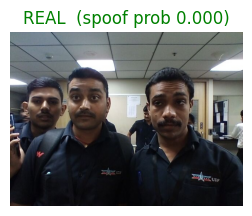

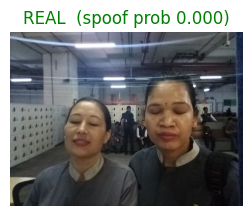

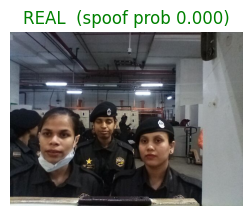

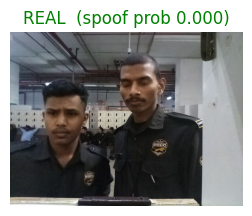

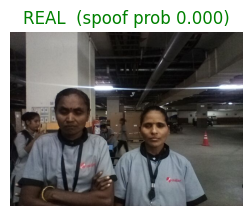

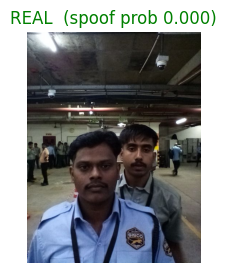

In [ ]:
from google.colab import files
import matplotlib.pyplot as plt

uploaded = files.upload()
for name in uploaded:
    label, p = predict(name)
    img = cv2.cvtColor(cv2.imread(name), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(3, 3)); plt.imshow(img); plt.axis("off")
    plt.title(f"{label}  (spoof prob {p:.3f})", color="red" if label == "SPOOF" else "green")
    plt.show()


Saving 6ac6e9282a92dc79eab61402_checkin.jpg to 6ac6e9282a92dc79eab61402_checkin.jpg
Saving 6ac5fbd0be00ad6709806a0a_checkin.jpg to 6ac5fbd0be00ad6709806a0a_checkin.jpg
Saving 6ac7a7910b3f3550e3313e80_checkin.jpg to 6ac7a7910b3f3550e3313e80_checkin.jpg
Saving 6ac7ae700b3f3550e3313f39_checkout.jpg to 6ac7ae700b3f3550e3313f39_checkout.jpg
Saving 6ac7b26275c9a02de55de714_checkin.jpg to 6ac7b26275c9a02de55de714_checkin.jpg
Saving 6ac7b1a4cf563e4bb7070938_checkin.jpg to 6ac7b1a4cf563e4bb7070938_checkin.jpg
Saving 6ac7aef575c9a02de55de6b9_checkin.jpg to 6ac7aef575c9a02de55de6b9_checkin.jpg
Saving 6ac7bd9d2a92dc79eab64a9c_checkin.jpg to 6ac7bd9d2a92dc79eab64a9c_checkin.jpg
Saving 6ac7c106b132bd70ecb5465d_checkin.jpg to 6ac7c106b132bd70ecb5465d_checkin (1).jpg
Saving e5841ad1-4d5a-4cf9-a4c6-f4a4f63e728b.jpeg to e5841ad1-4d5a-4cf9-a4c6-f4a4f63e728b.jpeg


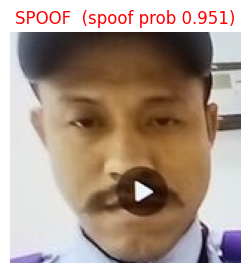

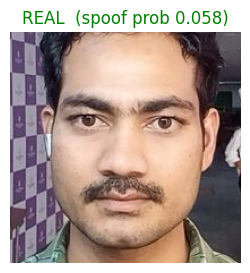

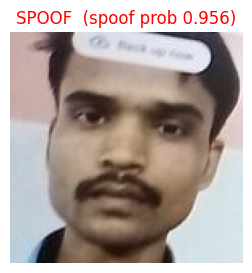

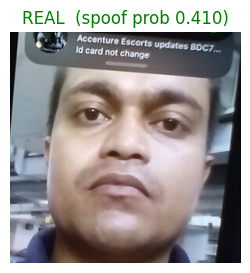

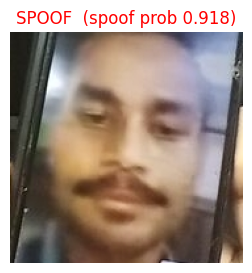

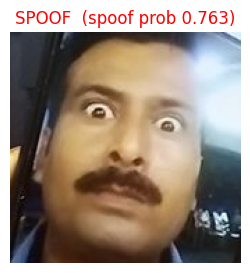

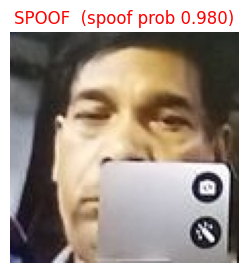

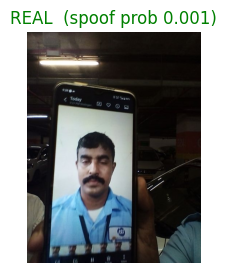

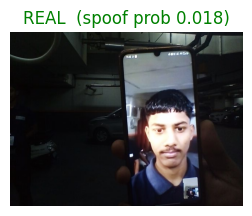

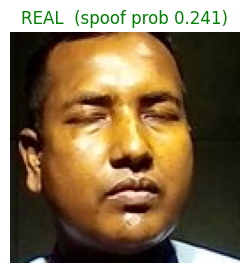

In [ ]:
from google.colab import files
import matplotlib.pyplot as plt

uploaded = files.upload()
for name in uploaded:
    label, p = predict(name)
    img = cv2.cvtColor(cv2.imread(name), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(3, 3)); plt.imshow(img); plt.axis("off")
    plt.title(f"{label}  (spoof prob {p:.3f})", color="red" if label == "SPOOF" else "green")
    plt.show()


In [ ]:
# ============================================================
# Image usage summary
# ============================================================
total_indexed = len(df_all)
pool_n        = len(pool)
holdout_n     = len(holdout)
dropped_n     = len(drop_log)

print(f"Indexed (all production face crops): {total_indexed}  "
      f"(real={int((df_all.label==0).sum())}, spoof={int((df_all.label==1).sum())})")
print(f"Dropped (unreadable/duplicate):      {dropped_n}")
print(f"Fine-tune pool:                      {pool_n}")
print(f"Real-only holdout (eval only):       {holdout_n}")
print(f"Not used anywhere:                   {total_indexed - pool_n - holdout_n - dropped_n}\n")

usage = pd.crosstab(pool.split, pool.label.map({0: "real", 1: "spoof"}),
                    margins=True, margins_name="total").reindex(["train", "val", "test", "total"])
print(usage.to_string())

# Cross-check: loaders see exactly these images
print(f"\nLoaders → train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)} | holdout {len(holdout_ds)}")
assert len(train_ds) + len(val_ds) + len(test_ds) == pool_n

Indexed (all production face crops): 5083  (real=4880, spoof=203)
Dropped (unreadable/duplicate):      0
Fine-tune pool:                      704
Real-only holdout (eval only):       4379
Not used anywhere:                   0

label  real  spoof  total
split                    
train   358    145    503
val      73     29    102
test     70     29     99
total   501    203    704

Loaders → train 503 | val 102 | test 99 | holdout 4379


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Tuned threshold (from val): 0.17  (meets APCER target)

===== TEST @0.50  (threshold=0.50, n=99: 70 real / 29 spoof) =====
Loss              : 0.3436
Accuracy          : 85.86%   (95% CI 77.65%–91.39%)
Balanced accuracy : 87.98%
Precision (spoof) : 69.23%
Recall (spoof)    : 93.10%
F1 (spoof)        : 79.41%
ROC-AUC           : 0.9512
APCER (spoof→real): 6.90%   (2 attacks accepted)
BPCER (real→spoof): 17.14%   (12 genuine rejected)
ACER              : 12.02%
              precision    recall  f1-score   support

        real     0.9667    0.8286    0.8923        70
       spoof     0.6923    0.9310    0.7941        29

    accuracy                         0.8586        99
   macro avg     0.8295    0.8798    0.8432        99
weighted avg     0.8863    0.8586    0.8635        99


===== TEST @tuned  (threshold=0.17, n=99: 70 real / 29 spoof) =====
Loss              : 0.3436
Accuracy          : 74.75%   (95% CI 65.38%–82.27%)
Balanced accuracy : 81.13%
Precision (spoof) : 53.85%
Recall 

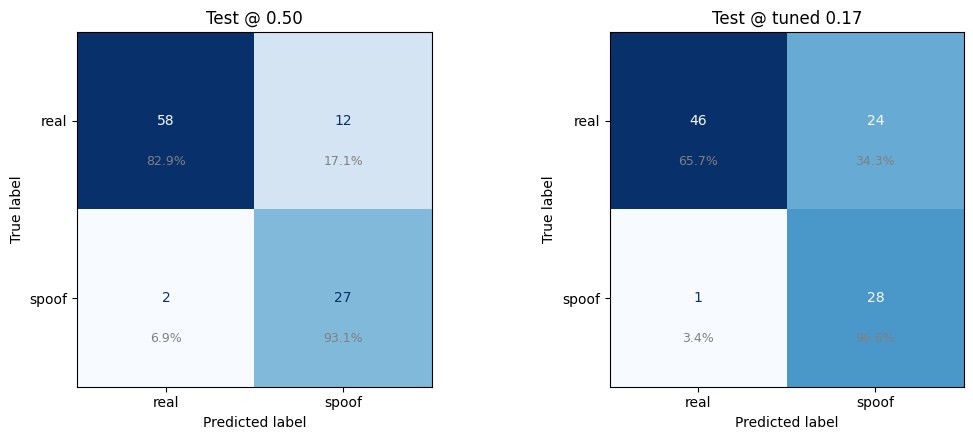

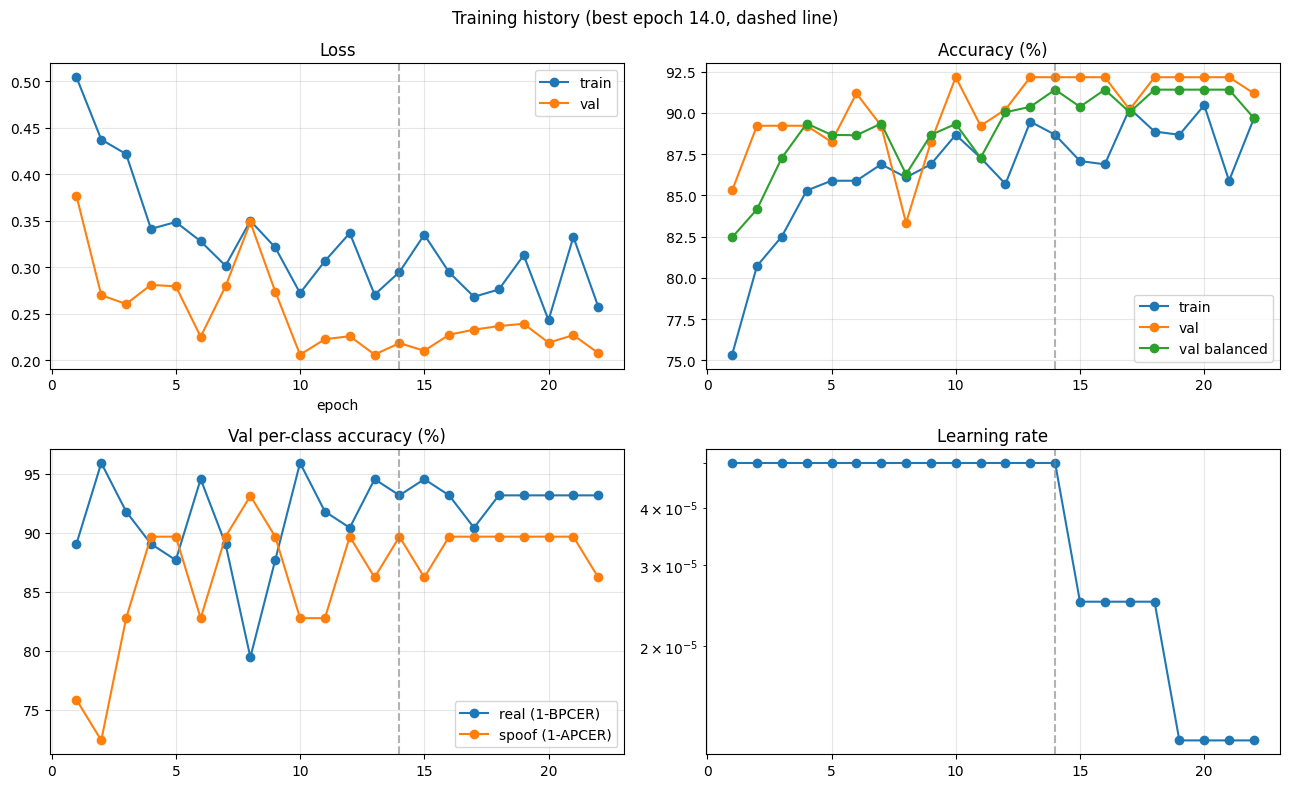

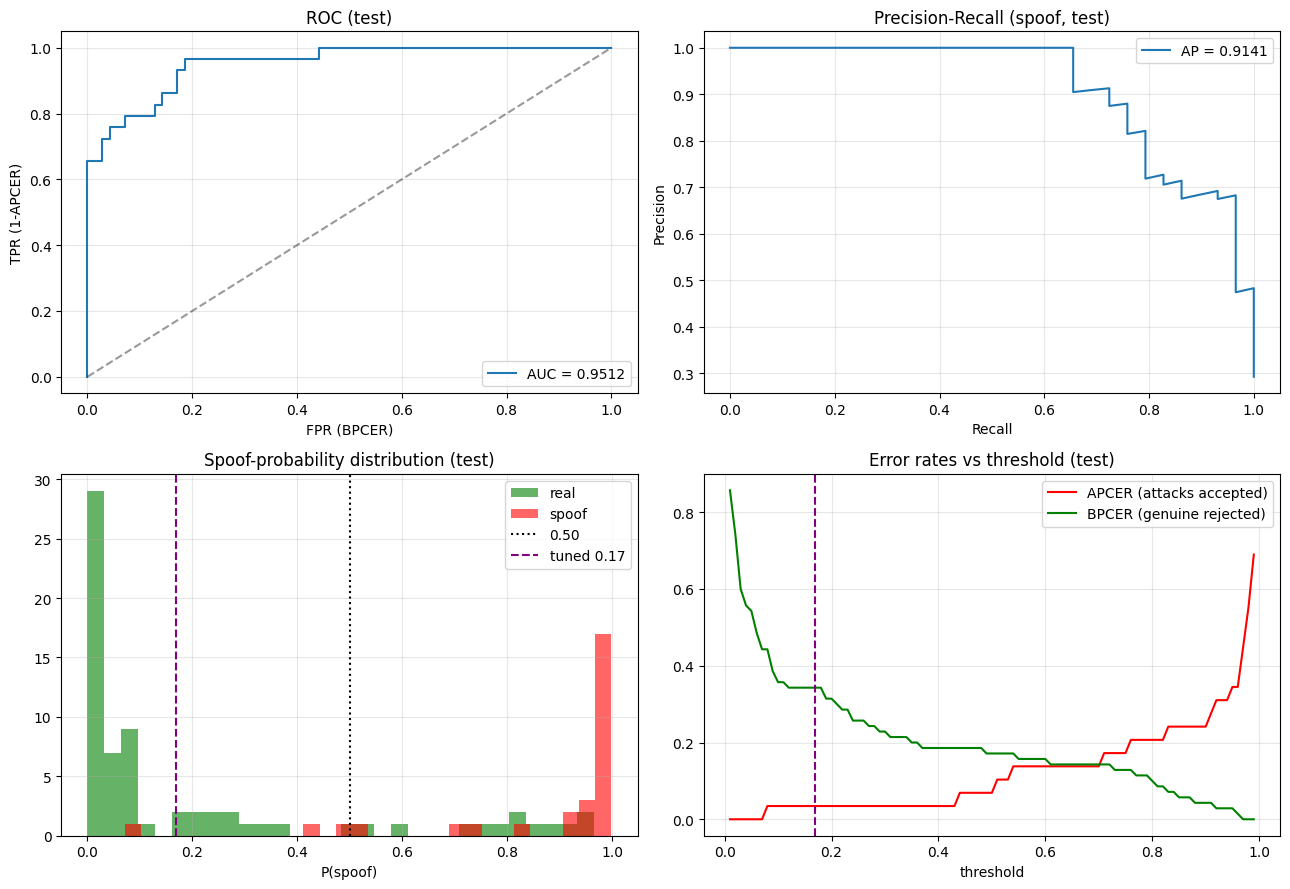

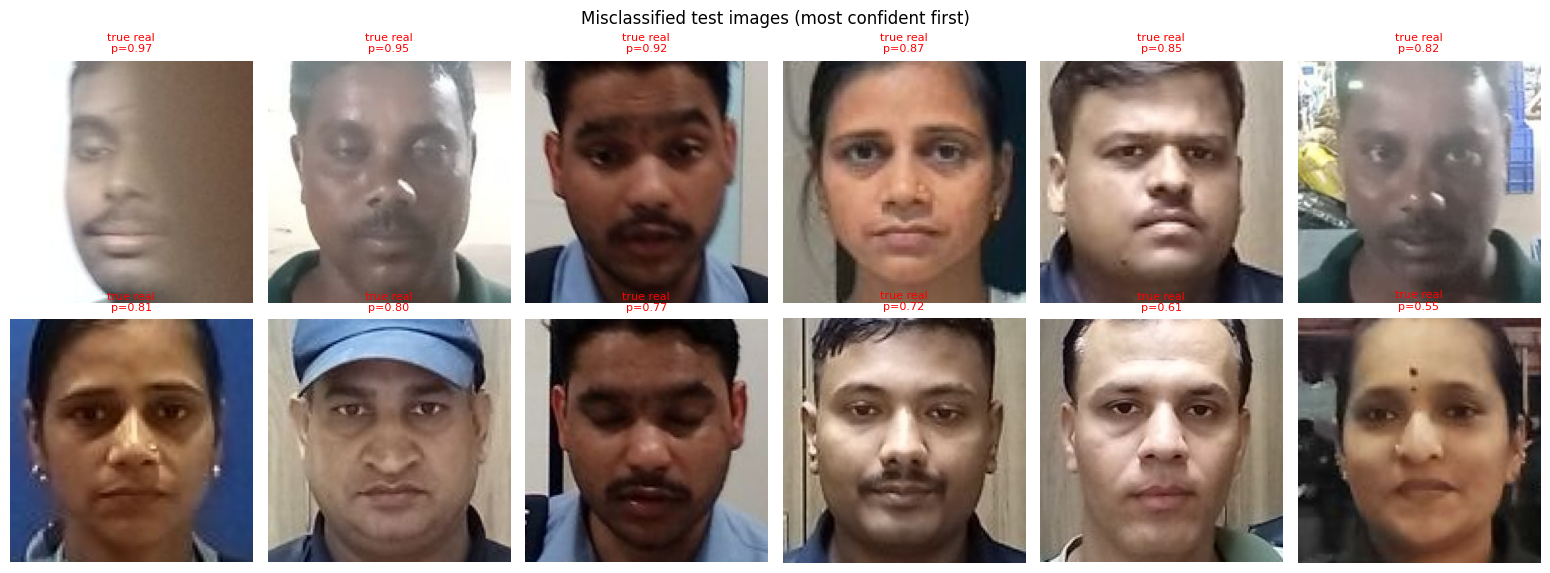

In [ ]:
# ===================== Full evaluation of fine-tuned model =====================
import json, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)
from statsmodels.stats.proportion import proportion_confint

# ---------- 1. Load best fine-tuned weights ----------
eval_model = MiniFASNetV2_Fixed(num_classes=2).to(DEVICE)
eval_model.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE, weights_only=True))
eval_model.eval()

@torch.no_grad()
def get_probs(model, loader):
    probs, ys, loss_sum, n = [], [], 0.0, 0
    crit = nn.CrossEntropyLoss(reduction="sum")
    for batch in loader:
        x, y = batch[0].to(DEVICE), batch[1].to(DEVICE)
        out = model(x)
        loss_sum += crit(out, y).item(); n += y.size(0)
        probs.append(F.softmax(out, 1)[:, 1].cpu().numpy()); ys.append(y.cpu().numpy())
    return np.concatenate(probs), np.concatenate(ys), loss_sum / n

val_p,  val_y,  val_loss  = get_probs(eval_model, val_loader)
test_p, test_y, test_loss = get_probs(eval_model, test_loader)

# ---------- 2. Pick threshold on VAL (APCER <= target, best bacc), apply to TEST ----------
APCER_T = globals().get("APCER_TARGET", 0.02)
cands = []
for t in np.linspace(0.01, 0.99, 99):
    pr = (val_p >= t).astype(int)
    apcer = ((pr == 0) & (val_y == 1)).sum() / max((val_y == 1).sum(), 1)
    cands.append((t, balanced_accuracy_score(val_y, pr), apcer))
feasible = [c for c in cands if c[2] <= APCER_T]
TUNED_T = (max(feasible, key=lambda c: c[1]) if feasible else max(cands, key=lambda c: c[1]))[0]
print(f"Tuned threshold (from val): {TUNED_T:.2f}  "
      f"{'(meets APCER target)' if feasible else '(APCER target NOT reachable — best bacc used)'}")

# ---------- 3. Metrics table ----------
def report(name, p, y, thr, loss):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    apcer, bpcer = fn / max(fn + tp, 1), fp / max(fp + tn, 1)
    lo, hi = proportion_confint((pred == y).sum(), len(y), method="wilson")
    print(f"\n===== {name}  (threshold={thr:.2f}, n={len(y)}: {(y==0).sum()} real / {(y==1).sum()} spoof) =====")
    print(f"Loss              : {loss:.4f}")
    print(f"Accuracy          : {accuracy_score(y, pred):.2%}   (95% CI {lo:.2%}–{hi:.2%})")
    print(f"Balanced accuracy : {balanced_accuracy_score(y, pred):.2%}")
    print(f"Precision (spoof) : {precision_score(y, pred, zero_division=0):.2%}")
    print(f"Recall (spoof)    : {recall_score(y, pred, zero_division=0):.2%}")
    print(f"F1 (spoof)        : {f1_score(y, pred, zero_division=0):.2%}")
    print(f"ROC-AUC           : {roc_auc_score(y, p):.4f}")
    print(f"APCER (spoof→real): {apcer:.2%}   ({fn} attacks accepted)")
    print(f"BPCER (real→spoof): {bpcer:.2%}   ({fp} genuine rejected)")
    print(f"ACER              : {(apcer + bpcer) / 2:.2%}")
    print(classification_report(y, pred, target_names=["real", "spoof"], digits=4, zero_division=0))
    return pred

test_pred_05  = report("TEST @0.50",  test_p, test_y, 0.5,     test_loss)
test_pred_tun = report("TEST @tuned", test_p, test_y, TUNED_T, test_loss)

# ---------- 4. Confusion matrices ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pred, title in [(axes[0], test_pred_05, "Test @ 0.50"),
                        (axes[1], test_pred_tun, f"Test @ tuned {TUNED_T:.2f}")]:
    cm = confusion_matrix(test_y, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["real", "spoof"]).plot(ax=ax, cmap="Blues", colorbar=False)
    for (i, j), v in np.ndenumerate(cm):   # add row % under counts
        ax.text(j, i + 0.25, f"{v / max(cm[i].sum(), 1):.1%}", ha="center", fontsize=9, color="gray")
    ax.set_title(title)
plt.tight_layout(); plt.show()

# ---------- 5. Training curves (loss, accuracy, per-class, LR) ----------
with open(HISTORY_PATH) as f:
    h = json.load(f)
ep = h["epoch"]; best_ep = ep[int(np.argmax(h["val_bacc"]))]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0,0].plot(ep, h["train_loss"], "o-", label="train"); axes[0,0].plot(ep, h["val_loss"], "o-", label="val")
axes[0,0].set_title("Loss"); axes[0,0].set_xlabel("epoch")
axes[0,1].plot(ep, h["train_acc"], "o-", label="train"); axes[0,1].plot(ep, h["val_acc"], "o-", label="val")
axes[0,1].plot(ep, h["val_bacc"], "o-", label="val balanced"); axes[0,1].set_title("Accuracy (%)")
axes[1,0].plot(ep, h["val_real_acc"], "o-", label="real (1-BPCER)")
axes[1,0].plot(ep, h["val_spoof_acc"], "o-", label="spoof (1-APCER)"); axes[1,0].set_title("Val per-class accuracy (%)")
axes[1,1].plot(ep, h["lr"], "o-"); axes[1,1].set_yscale("log"); axes[1,1].set_title("Learning rate")
for ax in axes.flat:
    ax.axvline(best_ep, ls="--", c="gray", alpha=.6); ax.grid(alpha=.3)
    if ax.get_legend_handles_labels()[0]: ax.legend()
plt.suptitle(f"Training history (best epoch {best_ep}, dashed line)"); plt.tight_layout(); plt.show()

# ---------- 6. ROC, Precision-Recall, score distribution, APCER/BPCER vs threshold ----------
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fpr, tpr, _ = roc_curve(test_y, test_p)
axes[0,0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(test_y, test_p):.4f}"); axes[0,0].plot([0,1],[0,1],"k--",alpha=.4)
axes[0,0].set(title="ROC (test)", xlabel="FPR (BPCER)", ylabel="TPR (1-APCER)")

prec, rec, _ = precision_recall_curve(test_y, test_p)
axes[0,1].plot(rec, prec, label=f"AP = {average_precision_score(test_y, test_p):.4f}")
axes[0,1].set(title="Precision-Recall (spoof, test)", xlabel="Recall", ylabel="Precision")

axes[1,0].hist(test_p[test_y == 0], bins=30, alpha=.6, label="real", color="green")
axes[1,0].hist(test_p[test_y == 1], bins=30, alpha=.6, label="spoof", color="red")
axes[1,0].axvline(0.5, c="k", ls=":", label="0.50"); axes[1,0].axvline(TUNED_T, c="purple", ls="--", label=f"tuned {TUNED_T:.2f}")
axes[1,0].set(title="Spoof-probability distribution (test)", xlabel="P(spoof)")

ts = np.linspace(0.01, 0.99, 99)
apcers = [((test_p < t) & (test_y == 1)).sum() / max((test_y == 1).sum(), 1) for t in ts]
bpcers = [((test_p >= t) & (test_y == 0)).sum() / max((test_y == 0).sum(), 1) for t in ts]
axes[1,1].plot(ts, apcers, label="APCER (attacks accepted)", c="red")
axes[1,1].plot(ts, bpcers, label="BPCER (genuine rejected)", c="green")
axes[1,1].axvline(TUNED_T, c="purple", ls="--"); axes[1,1].set(title="Error rates vs threshold (test)", xlabel="threshold")
for ax in axes.flat: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# ---------- 7. Most confident mistakes (visual check) ----------
paths = getattr(test_loader.dataset, "paths", None) or getattr(test_loader.dataset, "images", None)
wrong = np.where(test_pred_tun != test_y)[0]
wrong = wrong[np.argsort(-np.abs(test_p[wrong] - TUNED_T))][:12]   # most confident errors first
if paths is not None and len(wrong):
    import cv2
    cols = 6; rows = int(np.ceil(len(wrong) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 2.9 * rows), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, i in zip(axes.flat, wrong):
        img = cv2.imread(str(paths[i]))
        if img is not None: ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"true {'spoof' if test_y[i] else 'real'}\np={test_p[i]:.2f}", fontsize=8, color="red")
    plt.suptitle("Misclassified test images (most confident first)"); plt.tight_layout(); plt.show()
else:
    print(f"{len(wrong)} misclassified (image paths not available on dataset object for preview)")


In [ ]:
# ============================================================
# EVAL CELL 0 — Model definition (identical to training notebook)
# ============================================================
import torch
import torch.nn as nn

class MiniFASNetV2_Fixed(nn.Module):
    """MiniFASNetV2 for 224x224 input - FIXED"""

    def __init__(self, num_classes=2):
        super().__init__()

        # Depthwise Separable Convolutions
        self.conv1 = self._ds_conv(3, 8, 3, 1, 1)       # 224 → 224
        self.conv2 = self._ds_conv(8, 16, 3, 2, 1)      # 224 → 112
        self.conv3 = self._ds_conv(16, 32, 3, 1, 1)     # 112 → 112
        self.conv4 = self._ds_conv(32, 64, 3, 2, 1)     # 112 → 56
        self.conv5 = self._ds_conv(64, 128, 3, 1, 1)    # 56 → 56
        self.conv6 = self._ds_conv(128, 256, 3, 2, 1)   # 56 → 28
        self.conv7 = self._ds_conv(256, 256, 3, 1, 1)   # 28 → 28

        # Adaptive pooling handles any input size
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))     # Output: 1×1

        # FC layers
        self.fc1 = nn.Linear(256, 128)
        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, num_classes)

        self._init_weights()

    def _ds_conv(self, in_c, out_c, k, s, p):
        """Depthwise Separable Convolution"""
        return nn.Sequential(
            nn.Conv2d(in_c, in_c, k, s, p, groups=in_c, bias=False),
            nn.BatchNorm2d(in_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_c, out_c, 1, 1, 0, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True)
        )

    def _init_weights(self):
        """Kaiming initialization"""
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.conv5(x)
        x = self.conv6(x)
        x = self.conv7(x)

        x = self.avgpool(x)
        x = x.view(x.size(0), -1)      # (batch, 256)

        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

print("✓ MiniFASNetV2_Fixed defined")

✓ MiniFASNetV2_Fixed defined


In [ ]:
# ============================================================
# EVAL CELL A — Load fine-tuned model for inference testing
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, cv2, torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import confusion_matrix
from tqdm.auto import tqdm

DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RUN_DIR    = Path("/content/drive/MyDrive/finetune_runs/run_20261015_083814")
MODEL_PATH = RUN_DIR / "best_model_ft.pth"
THRESHOLD  = 0.5          # spoof if P(spoof) >= THRESHOLD
H_INPUT = W_INPUT = 224
BATCH_SIZE = 32

assert "MiniFASNetV2_Fixed" in dir(), "Run the cell that defines MiniFASNetV2_Fixed first"
assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

eval_model = MiniFASNetV2_Fixed(num_classes=2).to(DEVICE)
state = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True)
if isinstance(state, dict) and isinstance(state.get("model"), dict):   # tolerate wrapped checkpoints
    state = state["model"]
eval_model.load_state_dict(state, strict=True)
eval_model.eval()

with torch.no_grad():   # smoke test
    out = eval_model(torch.zeros(1, 3, H_INPUT, W_INPUT, device=DEVICE))
assert out.shape == (1, 2) and torch.isfinite(out).all()

print(f"✓ Loaded {MODEL_PATH.name} on {DEVICE} | "
      f"params: {sum(p.numel() for p in eval_model.parameters()):,} | threshold: {THRESHOLD}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


AssertionError: Run the cell that defines MiniFASNetV2_Fixed first

In [ ]:
# ============================================================
# EVAL CELL B — Inference on face crops + confusion matrix + % correctness
# ============================================================
class CropDataset(Dataset):
    """Same preprocessing as training eval: BGR, resize 224, scale to [-1, 1], CHW."""
    def __init__(self, paths, labels):
        self.paths, self.labels = list(paths), list(labels)
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = cv2.imread(str(self.paths[i]))
        if img is None:
            raise RuntimeError(f"Unreadable image: {self.paths[i]}")
        img = cv2.resize(img, (W_INPUT, H_INPUT)).astype(np.float32) / 127.5 - 1.0
        return torch.from_numpy(np.transpose(img, (2, 0, 1))), int(self.labels[i])

@torch.no_grad()
def predict_probs(model, paths, labels):
    loader = DataLoader(CropDataset(paths, labels), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=0)   # 0 workers avoids the worker-shutdown spam
    probs = []
    for x, _ in tqdm(loader, desc="Inference", leave=False):
        probs.append(F.softmax(model(x.to(DEVICE)), dim=1)[:, 1].cpu())
    return torch.cat(probs).numpy()

def pct(a, b):
    return 100.0 * a / b if b else float("nan")

def evaluate_set(name, df, thr=THRESHOLD, plot=True):
    paths, y = df["src_path"].values, df["label"].values.astype(int)
    p = predict_probs(eval_model, paths, y)
    pred = (p >= thr).astype(int)

    cm = confusion_matrix(y, pred, labels=[0, 1])        # rows = actual, cols = predicted
    tn, fp, fn, tp = cm.ravel()
    n_real, n_spoof = tn + fp, fn + tp

    real_acc  = pct(tn, n_real)                          # real correctly accepted
    spoof_acc = pct(tp, n_spoof)                         # spoof correctly caught (recall)
    res = {
        "set": name, "images": len(y), "real": n_real, "spoof": n_spoof,
        "accuracy_%":   pct(tn + tp, len(y)),
        "real_acc_%":   real_acc,
        "spoof_acc_%":  spoof_acc,
        "balanced_%":   np.nanmean([real_acc, spoof_acc]),
        "precision_%":  pct(tp, tp + fp),                # of flagged spoofs, how many are real spoofs
        "APCER_%":      pct(fn, n_spoof),                # spoof accepted as real
        "BPCER_%":      pct(fp, n_real),                 # real rejected as spoof
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

    print(f"\n══════ {name.upper()} ({len(y)} imgs: {n_real} real / {n_spoof} spoof) @ thr={thr} ══════")
    print(f"  Overall accuracy : {res['accuracy_%']:6.2f}%  ({tn + tp}/{len(y)} correct)")
    print(f"  Real accuracy    : {real_acc:6.2f}%  ({tn}/{n_real})")
    print(f"  Spoof accuracy   : {spoof_acc:6.2f}%  ({tp}/{n_spoof})")
    print(f"  Balanced accuracy: {res['balanced_%']:6.2f}%")
    print(f"  Spoof precision  : {res['precision_%']:6.2f}%")
    print(f"  APCER (spoof→real): {res['APCER_%']:5.2f}%  | BPCER (real→spoof): {res['BPCER_%']:5.2f}%")
    print(f"  Confusion matrix (rows=actual, cols=pred) [REAL, SPOOF]:\n{cm}")

    if plot:
        row_tot = cm.sum(axis=1, keepdims=True)
        row_pct = np.divide(cm, row_tot, out=np.zeros_like(cm, dtype=float), where=row_tot > 0) * 100
        fig, ax = plt.subplots(figsize=(4, 3.6))
        ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=100)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]}\n({row_pct[i, j]:.1f}%)", ha="center", va="center",
                        color="white" if row_pct[i, j] > 50 else "black", fontsize=11)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["REAL", "SPOOF"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["REAL", "SPOOF"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
        ax.set_title(f"{name} — bacc {res['balanced_%']:.2f}%")
        plt.tight_layout(); plt.show()

    mis = df.assign(prob_spoof=p, pred=pred)[pred != y]
    return res, mis, p

# ---- Evaluation sets (from the run's saved split — same data the model was trained/validated on) ----
splits  = pd.read_csv(RUN_DIR / "splits.csv")
holdout = pd.read_csv(RUN_DIR / "real_holdout.csv")

EVAL_SETS = {
    "test":         splits[splits.split == "test"],    # never seen in training — the honest number
    "val":          splits[splits.split == "val"],     # used for early stopping (slightly optimistic)
    "train":        splits[splits.split == "train"],   # sanity check for over/under-fitting
    "real_holdout": holdout,                           # 4,379 unseen real crops — false-alarm rate at scale
}

results, misclassified, probs_by_set = [], {}, {}
for name, df in EVAL_SETS.items():
    res, mis, p = evaluate_set(name, df)
    results.append(res); misclassified[name] = mis; probs_by_set[name] = p
    mis.to_csv(RUN_DIR / f"misclassified_{name}.csv", index=False)

In [ ]:
# ============================================================
# EVAL CELL C — Summary table + view misclassified TEST crops
# ============================================================
summary = pd.DataFrame(results).set_index("set")
cols = ["images", "real", "spoof", "accuracy_%", "real_acc_%", "spoof_acc_%",
        "balanced_%", "precision_%", "APCER_%", "BPCER_%", "TN", "FP", "FN", "TP"]
print(summary[cols].round(2).to_string())
summary.to_csv(RUN_DIR / "eval_summary.csv")
print(f"\n✓ Saved eval_summary.csv + misclassified_*.csv → {RUN_DIR}")

mis = misclassified["test"]
if len(mis):
    k = min(12, len(mis))
    fig, axes = plt.subplots(1, k, figsize=(2.2 * k, 2.8), squeeze=False)
    for ax, r in zip(axes[0], mis.head(k).itertuples()):
        ax.imshow(cv2.cvtColor(cv2.imread(r.src_path), cv2.COLOR_BGR2RGB)); ax.axis("off")
        ax.set_title(f"true {'SPOOF' if r.label else 'REAL'}\np_spoof={r.prob_spoof:.2f}",
                     fontsize=8, color="red")
    plt.suptitle("Misclassified TEST crops"); plt.tight_layout(); plt.show()
else:
    print("No misclassified test images 🎯")

In [ ]:
from google.colab import files
import matplotlib.pyplot as plt

uploaded = files.upload()
for name in uploaded:
    label, p = predict(name)
    img = cv2.cvtColor(cv2.imread(name), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(3, 3)); plt.imshow(img); plt.axis("off")
    plt.title(f"{label}  (spoof prob {p:.3f})", color="red" if label == "SPOOF" else "green")
    plt.show()


In [ ]:
# ===== PHASE 1 ANALYSIS — 1. setup + load the fine-tuned crop model and its starting point =====
from google.colab import drive
drive.mount('/content/drive')
import os, json, hashlib, math
from pathlib import Path
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, confusion_matrix,
                             classification_report, brier_score_loss)

DEVICE   = torch.device("cuda" if torch.cuda.is_available() else "cpu")
P1_RUN   = Path("/content/drive/MyDrive/finetune_runs/run_20261015_083814")
FT_PATH  = P1_RUN / "best_model_ft.pth"                                  # Phase 1 fine-tuned crop model (91.4% val bacc)
PRIOR    = Path("/content/drive/MyDrive/checkpoints/best_model.pth")      # its starting point (~85% model)
DS_ROOT  = Path("/content/drive/MyDrive/spoof_dataset")
OLD_REAL, OLD_SPOOF = Path("/content/drive/MyDrive/real"), Path("/content/drive/MyDrive/spoof")
OUT      = P1_RUN / "analysis"; OUT.mkdir(exist_ok=True)
H = W = 224; BATCH = 64; EXTS = {".jpg", ".jpeg", ".png", ".webp"}

class MiniFASNetV2_Fixed(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.conv1 = self._ds(3, 8, 3, 1, 1);    self.conv2 = self._ds(8, 16, 3, 2, 1)
        self.conv3 = self._ds(16, 32, 3, 1, 1);  self.conv4 = self._ds(32, 64, 3, 2, 1)
        self.conv5 = self._ds(64, 128, 3, 1, 1); self.conv6 = self._ds(128, 256, 3, 2, 1)
        self.conv7 = self._ds(256, 256, 3, 1, 1)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc1 = nn.Linear(256, 128); self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5); self.fc2 = nn.Linear(128, num_classes)
    def _ds(self, i, o, k, s, p):
        return nn.Sequential(nn.Conv2d(i, i, k, s, p, groups=i, bias=False), nn.BatchNorm2d(i), nn.ReLU(inplace=True),
                             nn.Conv2d(i, o, 1, 1, 0, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x):
        for b in ["conv1", "conv2", "conv3", "conv4", "conv5", "conv6", "conv7"]: x = getattr(self, b)(x)
        x = self.avgpool(x).flatten(1)
        return self.fc2(self.dropout(self.relu(self.fc1(x))))

def sha16(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()[:16]

def load_model(path):
    st = torch.load(path, map_location=DEVICE, weights_only=True)
    if isinstance(st, dict) and isinstance(st.get("model"), dict): st = st["model"]
    m = MiniFASNetV2_Fixed().to(DEVICE); m.load_state_dict(st, strict=True); m.eval()
    with torch.no_grad(): assert torch.isfinite(m(torch.zeros(1, 3, H, W, device=DEVICE))).all()
    return m

MODELS = {"prior": load_model(PRIOR), "phase1_ft": load_model(FT_PATH)}
for k, p in [("prior", PRIOR), ("phase1_ft", FT_PATH)]:
    print(f"✓ {k:10s} {p}  sha {sha16(p)}  {p.stat().st_size/1024:.0f} KB")
print("files in Phase 1 run:", sorted(f.name for f in P1_RUN.iterdir()))


ValueError: mount failed

In [1]:
# ===== LOAD "spoof_dataset new/face" (Colab) =====
from google.colab import drive
drive.mount('/content/drive')

import re
from pathlib import Path
import numpy as np, pandas as pd, cv2
from tqdm.auto import tqdm

FACE_ROOT = Path("/content/drive/MyDrive/spoof_dataset new/face")     # space in the name is fine with Path
assert FACE_ROOT.exists(), f"Not found: {FACE_ROOT}"
EXTS = {".jpg", ".jpeg", ".png", ".webp"}

# see what class folders are actually there (e.g. real / spoof / spoof>>>)
SUB = {p.name: p for p in FACE_ROOT.iterdir() if p.is_dir()}
print("subfolders:", {n: sum(1 for f in p.iterdir() if f.suffix.lower() in EXTS) for n, p in SUB.items()})

REAL_DIR  = SUB["real"]
spoof_alt = [p for n, p in SUB.items() if n.lower().startswith("spoof") and n.lower() != "spoof"]
SPOOF_DIR = spoof_alt[0] if spoof_alt else SUB["spoof"]                # prefer the corrected 'spoof>>>' if present
print("using:", REAL_DIR.name, "/", SPOOF_DIR.name)

LOG_RE = re.compile(r"^(?P<log>.+)_(?P<side>checkin|checkout)$", re.IGNORECASE)
def index(d, label):
    rows = []
    for p in sorted(d.iterdir()):
        if p.suffix.lower() not in EXTS: continue
        m = LOG_RE.match(p.stem)
        rows.append({"path": str(p), "fname": p.name, "label": label,
                     "log_id": m["log"] if m else p.stem, "side": m["side"].lower() if m else "unknown"})
    return rows

FACE = pd.DataFrame(index(REAL_DIR, 0) + index(SPOOF_DIR, 1))
print(FACE.label.value_counts().rename({0: "real", 1: "spoof"}).to_dict(),
      "| log_ids:", FACE.log_id.nunique(), "| unparsed names:", int((FACE.side == "unknown").sum()))

# quick readability + size check on a sample
s = FACE.sample(min(200, len(FACE)), random_state=0)
shapes = [cv2.imread(p).shape[:2] if cv2.imread(p) is not None else None for p in tqdm(s.path, desc="check")]
print("unreadable:", sum(x is None for x in shapes),
      "| sizes (h×w):", pd.Series([f"{h}x{w}" for h, w in filter(None, shapes)]).value_counts().head(5).to_dict())


MessageError: Error: credential propagation was unsuccessful

In [2]:
# ===== LoRA PIPELINE — STEP 0: inspect both datasets + runtime =====
from google.colab import drive; drive.mount('/content/drive')
from pathlib import Path
import torch
EXTS = {".jpg", ".jpeg", ".png", ".webp"}
for root in [Path("/content/drive/MyDrive/spoof_dataset"), Path("/content/drive/MyDrive/spoof_dataset new")]:
    print("==", root, "exists:", root.exists())
    if not root.exists(): continue
    for kind in sorted(d for d in root.iterdir() if d.is_dir()):
        for sub in sorted(d for d in kind.iterdir() if d.is_dir()):
            n = sum(1 for f in sub.iterdir() if f.suffix.lower() in EXTS)
            print(f"   {kind.name}/{sub.name}: {n}")
print("base ckpt exists:", Path("/content/drive/MyDrive/checkpoints/best_model.pth").exists())
print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "(CPU runtime)")


Mounted at /content/drive
== /content/drive/MyDrive/spoof_dataset exists: True
   face/real: 4904
   face/spoof: 203
   full/real: 4879
   full/spoof: 203
   full/spoof>>>: 313
== /content/drive/MyDrive/spoof_dataset new exists: True
   face/real: 2214
   face/spoof: 320
   full/real: 2214
   full/spoof: 320
base ckpt exists: True
GPU: True Tesla T4


In [3]:
# ===== LoRA 2-PHASE — L0: CONFIG (Phase 1 = spoof_dataset 203 spoof, Phase 2 = spoof_dataset new 320 spoof) =====
MODEL_KIND  = "crop"          # "crop" = MiniFASNetV2 on face crops | "full" = two-branch RGB + moire on full frames
PHASE2_DATA = "cumulative"    # "cumulative" = Phase-1 train + Phase-2 train | "new_only" = Phase-2 train only

from google.colab import drive; drive.mount('/content/drive')
import os, re, json, math, random, hashlib, collections, time, copy
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
from pathlib import Path
from datetime import datetime
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt

MYDRIVE = Path("/content/drive/MyDrive")
ROOT_A, SPOOF_A, N_REAL_A = MYDRIVE / "spoof_dataset",     "spoof", 500    # Phase 1: 203 spoof + ~500 real
ROOT_B, SPOOF_B, N_REAL_B = MYDRIVE / "spoof_dataset new", "spoof", 640    # Phase 2: 320 spoof + ~640 real
BASE_CKPT = MYDRIVE / "checkpoints/best_model.pth"; BASE_SHA_PREFIX = "fe5574c03afc8c11"   # 85% base, never modified
PREV_CROP_FT     = MYDRIVE / "finetune_runs/run_20261015_083814/best_model_ft.pth"          # previous full fine-tune (crop)
PREV_CROP_SPLITS = MYDRIVE / "finetune_runs/run_20261015_083814/splits.csv"
PREV_FULL_FT     = MYDRIVE / "checkpoints_fullframe_moire/run_20261023_075249/best.pth"     # previous full fine-tune (full)

RUN_DIR = MYDRIVE / "lora_runs" / f"{MODEL_KIND}_2phase_{datetime.now():%Y%m%d_%H%M%S}"
RUN_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
EXTS = {".jpg", ".jpeg", ".png", ".webp"}
CROP_SIZE, GLOBAL_SIZE, PATCH, SPEC, GRID, N_TRAIN_PATCH = 224, 320, 256, 128, 3, 4

# ---- LoRA ----
LORA_R, LORA_ALPHA, LORA_DROPOUT = 8, 16, 0.05
BITFIT = False                     # True: also train backbone BN gamma/beta (2,534 params)
LR_NEW, LR_LORA, LR_BITFIT = 3e-4, 5e-4, 1e-3

# ---- phases ----
EPOCHS_P1, WARMUP_P1 = 30, 5       # Phase 1: epochs 1-5 head/new layers only, then + LoRA adapters
EPOCHS_P2, LR_P2_SCALE = 20, 0.5   # Phase 2: continue the same adapters at half LR
FORGET_TOL = 0.02                  # Phase-2 epochs may not drop Phase-1 val AUC by more than this
PATIENCE, MIN_DELTA = 7, 1e-3
BATCH, SAMPLER_POWER, LABEL_SMOOTH, GRAD_CLIP, WD = 16, 0.5, 0.05, 2.0, 1e-4
APCER_TARGET, HOLDOUT_MAX = 0.05, 1500

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP, NUM_WORKERS, TWO_BRANCH = DEVICE.type == "cuda", 2, MODEL_KIND == "full"
print(f"MODEL_KIND={MODEL_KIND} | PHASE2_DATA={PHASE2_DATA} | device={DEVICE} | run dir: {RUN_DIR}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MODEL_KIND=crop | PHASE2_DATA=cumulative | device=cuda | run dir: /content/drive/MyDrive/lora_runs/crop_2phase_20261105_042530


In [4]:
# ===== LoRA 2-PHASE — L1: DATASETS A (203) + B (320), GROUP SPLITS, CROSS-PHASE LEAKAGE CONTROL =====
def list_imgs(d): return sorted(p for p in Path(d).iterdir() if p.suffix.lower() in EXTS)
LOG_RE = re.compile(r"^(?P<log>.+)_(checkin|checkout)$", re.IGNORECASE)
def log_of(p):
    m = LOG_RE.match(Path(p).stem); return m["log"] if m else Path(p).stem

def pick_fold(idx, y, g, k):
    sgkf = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=SEED)
    tr, ts = y.mean(), 1.0 / k
    return min(sgkf.split(idx, y, g), key=lambda f: abs(y[f[1]].mean() - tr) + abs(len(f[1]) / len(y) - ts))

def build_pool(root, spoof_name, n_real, tag):
    """All spoof sessions (whole) + real-only sessions until ~n_real real; then stratified GROUP split ~72/14/14."""
    full = root / "full"
    df = pd.DataFrame([(p.name, 0) for p in list_imgs(full / "real")] +
                      [(p.name, 1) for p in list_imgs(full / spoof_name)], columns=["fname", "label"])
    df["log"], df["ds"] = df.fname.map(log_of), tag
    has_sp = df.groupby("log").label.max()
    sp_logs, ro_logs = sorted(has_sp[has_sp == 1].index), sorted(has_sp[has_sp == 0].index)
    need = max(0, n_real - int((df.log.isin(sp_logs) & (df.label == 0)).sum()))
    sizes = df[df.log.isin(ro_logs)].groupby("log").size()
    sh = ro_logs[:]; random.Random(SEED).shuffle(sh)
    chosen, n = [], 0
    for lg in sh:
        if n >= need: break
        chosen.append(lg); n += int(sizes[lg])
    pool = df[df.log.isin(set(sp_logs) | set(chosen))].reset_index(drop=True)
    y, g, i = pool.label.values, pool.log.values, np.arange(len(pool))
    r_rel, t_rel = pick_fold(i, y, g, 7); te, rest = i[t_rel], i[r_rel]
    tr_rel, va_rel = pick_fold(rest, y[rest], g[rest], 6)
    pool["split"] = ""
    pool.loc[rest[tr_rel], "split"] = "train"; pool.loc[rest[va_rel], "split"] = "val"; pool.loc[te, "split"] = "test"
    spare = df[(df.label == 0) & df.log.isin(set(ro_logs) - set(chosen))]
    mixed = int((df.groupby("log").label.nunique() > 1).sum())
    print(f"[{tag}] {root.name}: real={int((df.label==0).sum())} spoof={int((df.label==1).sum())} | "
          f"pool real={int((pool.label==0).sum())} spoof={int((pool.label==1).sum())} | mixed sessions={mixed}")
    for s in ["train", "val", "test"]:
        d = pool[pool.split == s]
        print(f"     {s:5s}: real={int((d.label==0).sum()):4d} spoof={int((d.label==1).sum()):4d} sessions={d.log.nunique()}")
    return pool, spare

poolA, spareA = build_pool(ROOT_A, SPOOF_A, N_REAL_A, "A")
poolB, spareB = build_pool(ROOT_B, SPOOF_B, N_REAL_B, "B")
assert int((poolA.label == 1).sum()) == 203 and int((poolB.label == 1).sum()) == 320

print(f"Sessions in both pools: {len(set(poolA.log) & set(poolB.log))} | "
      f"same filename in both pools: {len(set(poolA.fname) & set(poolB.fname))}")

# ---- leakage control: a val/test session of EITHER dataset is never trained on in ANY phase ----
eval_logs = set(poolA.loc[poolA.split != "train", "log"]) | set(poolB.loc[poolB.split != "train", "log"])
p1 = poolA[(poolA.split == "train") & ~poolA.log.isin(eval_logs)]
p2_new = poolB[(poolB.split == "train") & ~poolB.log.isin(eval_logs)]
p2 = pd.concat([p2_new, p1]).drop_duplicates("fname", keep="first") if PHASE2_DATA == "cumulative" else p2_new
print(f"Phase-1 train: {len(p1)} (removed {int((poolA.split=='train').sum()) - len(p1)} rows in other eval sessions)")
print(f"Phase-2 train ({PHASE2_DATA}): {len(p2)} (B rows removed: {int((poolB.split=='train').sum()) - len(p2_new)})")

# ---- real-only holdout: real sessions from both datasets that are in neither pool ----
pool_logs = set(poolA.log) | set(poolB.log)
spare = pd.concat([spareA, spareB]); spare = spare[~spare.log.isin(pool_logs)]
hold = spare.sample(min(HOLDOUT_MAX, len(spare)), random_state=SEED)

# ---- resolve to face crops (crop) or full frames (full) ----
kind_dir = "full" if TWO_BRANCH else "face"
EXIST = {}
for tag, root, sp in [("A", ROOT_A, SPOOF_A), ("B", ROOT_B, SPOOF_B)]:
    for lab, sub in [(0, "real"), (1, sp)]:
        EXIST[(tag, lab)] = (root / kind_dir / sub, set(os.listdir(root / kind_dir / sub)))

def to_items(df):
    out, logs, miss = [], [], 0
    for f, y, lg, ds in zip(df.fname, df.label, df.log, df.ds):
        folder, names = EXIST[(ds, int(y))]
        if f in names: out.append((str(folder / f), int(y))); logs.append(lg)
        else: miss += 1
    return out, np.array(logs), miss

SETS, LOGS = {}, {}
for k, df in {"P1_train": p1, "P2_train": p2,
              "A_val": poolA[poolA.split == "val"], "A_test": poolA[poolA.split == "test"],
              "B_val": poolB[poolB.split == "val"], "B_test": poolB[poolB.split == "test"],
              "holdout": hold}.items():
    SETS[k], LOGS[k], miss = to_items(df)
    c = collections.Counter(y for _, y in SETS[k])
    print(f"{k:9s}: real={c[0]:5d} spoof={c[1]:4d}" + (f"  (missing {kind_dir} files: {miss})" if miss else ""))
pd.DataFrame([(k, p, y) for k, v in SETS.items() for p, y in v], columns=["set", "path", "label"]) \
  .to_csv(RUN_DIR / "sets.csv", index=False)
print("✓ sets.csv saved")


[A] spoof_dataset: real=4879 spoof=203 | pool real=501 spoof=203 | mixed sessions=189
     train: real= 358 spoof= 145 sessions=260
     val  : real=  73 spoof=  29 sessions=53
     test : real=  70 spoof=  29 sessions=53
[B] spoof_dataset new: real=2214 spoof=320 | pool real=641 spoof=320 | mixed sessions=269
     train: real= 460 spoof= 229 sessions=360
     val  : real=  91 spoof=  46 sessions=72
     test : real=  90 spoof=  45 sessions=71
Sessions in both pools: 0 | same filename in both pools: 0
Phase-1 train: 503 (removed 0 rows in other eval sessions)
Phase-2 train (cumulative): 1192 (B rows removed: 0)
P1_train : real=  358 spoof= 145
P2_train : real=  818 spoof= 374
A_val    : real=   73 spoof=  29
A_test   : real=   70 spoof=  29
B_val    : real=   91 spoof=  46
B_test   : real=   90 spoof=  45
holdout  : real= 1500 spoof=   0
✓ sets.csv saved


In [5]:
# ===== LoRA 2-PHASE — L2: PREPROCESSING + DATASETS + LOADERS =====
def load_bgr(path):
    with Image.open(path) as im:
        return cv2.cvtColor(np.asarray(ImageOps.exif_transpose(im).convert("RGB")), cv2.COLOR_RGB2BGR)

def letterbox(img, size):
    h, w = img.shape[:2]; s = size / max(h, w)
    r = cv2.resize(img, (max(1, round(w * s)), max(1, round(h * s))), interpolation=cv2.INTER_AREA)
    c = np.zeros((size, size, 3), np.uint8); y0, x0 = (size - r.shape[0]) // 2, (size - r.shape[1]) // 2
    c[y0:y0 + r.shape[0], x0:x0 + r.shape[1]] = r
    return c

def random_zoom(img, lo=0.6, hi=1.6):                 # breaks the face-size shortcut (RGB branch only)
    s = np.random.uniform(lo, hi); h, w = img.shape[:2]
    if s >= 1:
        ch, cw = int(h / s), int(w / s); y0, x0 = np.random.randint(0, h - ch + 1), np.random.randint(0, w - cw + 1)
        return img[y0:y0 + ch, x0:x0 + cw]
    ph, pw = int(h * (1 / s - 1) / 2), int(w * (1 / s - 1) / 2)
    return cv2.copyMakeBorder(img, ph, ph, pw, pw, cv2.BORDER_REFLECT)

_HANN = {}
def spectrum(patch):                                  # log-magnitude FFT of a NATIVE-resolution patch
    P = patch.shape[0]
    if P not in _HANN: _HANN[P] = np.outer(np.hanning(P), np.hanning(P)).astype(np.float32)
    g = patch.astype(np.float32); g -= g.mean()
    S = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(g * _HANN[P]))))
    if P != SPEC: S = cv2.resize(S, (SPEC, SPEC), interpolation=cv2.INTER_AREA)   # resizes the SPECTRUM, not the image
    return ((S - S.mean()) / (S.std() + 1e-6)).astype(np.float32)

def native_patches(gray, train):
    h, w = gray.shape; P = min(PATCH, h, w)
    if train:
        ys = np.clip(np.random.normal((h - P) / 2, (h - P) / 4 + 1, N_TRAIN_PATCH), 0, h - P).astype(int)
        xs = np.clip(np.random.normal((w - P) / 2, (w - P) / 4 + 1, N_TRAIN_PATCH), 0, w - P).astype(int)
        pos = list(zip(ys, xs))
    else:
        pos = [(y, x) for y in np.linspace(0, h - P, GRID).astype(int) for x in np.linspace(0, w - P, GRID).astype(int)]
    return [gray[y:y + P, x:x + P] for y, x in pos]

def crop_tf(img, train):                              # same preprocessing/augmentation as the base model's training
    img = cv2.resize(img, (CROP_SIZE, CROP_SIZE))
    if train:
        if np.random.rand() > 0.5: img = cv2.convertScaleAbs(img, alpha=np.random.uniform(0.8, 1.2), beta=0)
        if np.random.rand() > 0.5: img = cv2.flip(img, 1)
        if np.random.rand() > 0.5:
            M = cv2.getRotationMatrix2D((CROP_SIZE / 2, CROP_SIZE / 2), np.random.uniform(-15, 15), 1.0)
            img = cv2.warpAffine(img, M, (CROP_SIZE, CROP_SIZE))
    img = img.astype(np.float32) / 127.5 - 1.0
    return torch.from_numpy(img.transpose(2, 0, 1))

class SpoofDS(Dataset):
    def __init__(self, items, train, two_branch): self.items, self.train, self.two_branch = items, train, two_branch
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        path, y = self.items[i]
        if not self.two_branch:
            img = cv2.imread(path)
            if img is None: raise RuntimeError(f"Unreadable: {path}")
            return crop_tf(img, self.train), y
        img = load_bgr(path); gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        if self.train and np.random.rand() < 0.5: gray = cv2.flip(gray, 1)       # moire branch: flip only
        spec = np.stack([spectrum(p) for p in native_patches(gray, self.train)])[:, None]
        g = img
        if self.train:
            g = random_zoom(g)
            if np.random.rand() < 0.5: g = cv2.flip(g, 1)
            if np.random.rand() < 0.5:
                g = cv2.convertScaleAbs(g, alpha=np.random.uniform(0.85, 1.15), beta=np.random.uniform(-12, 12))
        g = letterbox(g, GLOBAL_SIZE).astype(np.float32) / 127.5 - 1.0
        return torch.from_numpy(g.transpose(2, 0, 1)), torch.from_numpy(spec), y

def make_loader(items, train, two_branch=None):
    two_branch = TWO_BRANCH if two_branch is None else two_branch
    kw = dict(batch_size=BATCH, num_workers=NUM_WORKERS, pin_memory=USE_AMP, persistent_workers=train and NUM_WORKERS > 0)
    ds = SpoofDS(items, train, two_branch)
    if not train: return DataLoader(ds, shuffle=False, **kw)
    tc = collections.Counter(y for _, y in items)
    w = [tc[y] ** -SAMPLER_POWER for _, y in items]                              # softened balancing (~40% spoof)
    return DataLoader(ds, sampler=WeightedRandomSampler(w, len(items), replacement=True,
                      generator=torch.Generator().manual_seed(SEED)), drop_last=True, **kw)

_b = next(iter(make_loader(SETS["P1_train"], True)))
print("train batch:", [tuple(t.shape) for t in _b[:-1]], "| spoof in batch:", int(_b[-1].sum()), "/", len(_b[-1]))


train batch: [(16, 3, 224, 224)] | spoof in batch: 5 / 16


In [6]:
# ===== LoRA 2-PHASE — L3: MODELS + LoRA LAYERS =====
BLOCKS = ["conv1", "conv2", "conv3", "conv4", "conv5", "conv6", "conv7"]

class MiniFASNetV2_Fixed(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.conv1 = self._ds(3, 8, 3, 1, 1);    self.conv2 = self._ds(8, 16, 3, 2, 1)
        self.conv3 = self._ds(16, 32, 3, 1, 1);  self.conv4 = self._ds(32, 64, 3, 2, 1)
        self.conv5 = self._ds(64, 128, 3, 1, 1); self.conv6 = self._ds(128, 256, 3, 2, 1)
        self.conv7 = self._ds(256, 256, 3, 1, 1)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc1 = nn.Linear(256, 128); self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5); self.fc2 = nn.Linear(128, num_classes)
    def _ds(self, i, o, k, s, p):
        return nn.Sequential(nn.Conv2d(i, i, k, s, p, groups=i, bias=False), nn.BatchNorm2d(i), nn.ReLU(inplace=True),
                             nn.Conv2d(i, o, 1, 1, 0, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def features(self, x):
        for b in BLOCKS: x = getattr(self, b)(x)
        return self.avgpool(x).flatten(1)
    def forward(self, x): return self.fc2(self.dropout(self.relu(self.fc1(self.features(x)))))

def cbr(i, o, s): return nn.Sequential(nn.Conv2d(i, o, 3, s, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class FullFrameMoireNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.rgb = MiniFASNetV2_Fixed()
        self.moire = nn.Sequential(cbr(1, 16, 2), cbr(16, 32, 2), cbr(32, 64, 2), cbr(64, 128, 2), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Sequential(nn.Linear(384, 128), nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(128, 2))
    def rgb_feats(self, x): return self.rgb.features(x)
    def forward(self, glob, spec):
        B, N = spec.shape[:2]
        m = self.moire(spec.flatten(0, 1)).flatten(1).view(B, N, -1).mean(1)     # average over patches
        return self.head(torch.cat([self.rgb_feats(glob), m], 1))

class LoRAConv1x1(nn.Module):
    """y = W x + (alpha/r)·B(A(x)); W frozen; B = 0 at start -> identical to the base model at epoch 0."""
    def __init__(self, base, r, alpha, dropout):
        super().__init__()
        assert base.kernel_size == (1, 1) and base.groups == 1
        self.base, self.scale, self.merged = base, alpha / r, False
        for p in self.base.parameters(): p.requires_grad = False
        self.A = nn.Conv2d(base.in_channels, r, 1, bias=False); self.B = nn.Conv2d(r, base.out_channels, 1, bias=False)
        nn.init.kaiming_uniform_(self.A.weight, a=math.sqrt(5)); nn.init.zeros_(self.B.weight)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        y = self.base(x)
        return y if self.merged else y + self.B(self.A(self.drop(x))) * self.scale
    @torch.no_grad()
    def merge(self):
        self.base.weight += ((self.B.weight.flatten(1) @ self.A.weight.flatten(1)) * self.scale).view_as(self.base.weight)
        self.merged = True

class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha, dropout):
        super().__init__()
        self.base, self.scale, self.merged = base, alpha / r, False
        for p in self.base.parameters(): p.requires_grad = False
        self.A = nn.Linear(base.in_features, r, bias=False); self.B = nn.Linear(r, base.out_features, bias=False)
        nn.init.kaiming_uniform_(self.A.weight, a=math.sqrt(5)); nn.init.zeros_(self.B.weight)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        y = self.base(x)
        return y if self.merged else y + self.B(self.A(self.drop(x))) * self.scale
    @torch.no_grad()
    def merge(self): self.base.weight += (self.B.weight @ self.A.weight) * self.scale; self.merged = True

def adapter_params(module):
    return [p for m in module.modules() if isinstance(m, (LoRAConv1x1, LoRALinear))
              for p in list(m.A.parameters()) + list(m.B.parameters())]

def freeze_bn_stats(backbone):                        # call AFTER every model.train()
    for m in backbone.modules():
        if isinstance(m, nn.BatchNorm2d): m.eval()

def merge_and_unload(single):                          # fold B·A into W -> plain MiniFASNetV2 again
    for b in BLOCKS:
        seq = getattr(single, b)
        if isinstance(seq[3], LoRAConv1x1): seq[3].merge(); seq[3] = seq[3].base
    for n in ["fc1", "fc2"]:
        m = getattr(single, n)
        if isinstance(m, LoRALinear): m.merge(); setattr(single, n, m.base)
print("✓ models + LoRA defined")


✓ models + LoRA defined


In [7]:
# ===== LoRA 2-PHASE — L4: BUILD LoRA MODEL FROM THE 85% BASE + METRIC HELPERS + BASELINE =====
sha = hashlib.sha256(BASE_CKPT.read_bytes()).hexdigest()
assert sha.startswith(BASE_SHA_PREFIX), f"best_model.pth changed (sha {sha[:16]}) — not the 85% base"
base_state = torch.load(BASE_CKPT, map_location="cpu", weights_only=False)
if isinstance(base_state, dict) and "state_dict" in base_state: base_state = base_state["state_dict"]

def build_model():
    if MODEL_KIND == "crop":
        m = MiniFASNetV2_Fixed(); m.load_state_dict(base_state, strict=True); bb = m
    else:
        m = FullFrameMoireNet(); m.rgb.load_state_dict(base_state, strict=True); bb = m.rgb
    for p in bb.parameters(): p.requires_grad = False                  # whole pretrained base frozen
    for b in BLOCKS:                                                     # LoRA on the 7 pointwise (1x1) convs
        seq = getattr(bb, b); seq[3] = LoRAConv1x1(seq[3], LORA_R, LORA_ALPHA, LORA_DROPOUT)
    if MODEL_KIND == "crop":
        m.fc1 = LoRALinear(m.fc1, LORA_R, LORA_ALPHA, LORA_DROPOUT)
    return m.to(DEVICE), bb

def param_sets(m, bb):
    head = (adapter_params(m.fc1) + list(m.fc2.parameters())) if MODEL_KIND == "crop" \
           else (list(m.moire.parameters()) + list(m.head.parameters()))
    conv = [p for b in BLOCKS for p in adapter_params(getattr(bb, b))]
    bit  = [q for b in BLOCKS for mm in getattr(bb, b).modules() if isinstance(mm, nn.BatchNorm2d) for q in (mm.weight, mm.bias)]
    return head, conv, bit

def set_mode(mode):                       # "warmup" = head / new layers only | "lora" = + backbone adapters
    for p in HEAD: p.requires_grad = True
    for p in CONV: p.requires_grad = mode == "lora"
    for p in BIT:  p.requires_grad = mode == "lora" and BITFIT

base_model = MiniFASNetV2_Fixed().to(DEVICE); base_model.load_state_dict(base_state, strict=True); base_model.eval()
model, backbone = build_model()
HEAD, CONV, BIT = param_sets(model, backbone)
cnt = lambda ps: sum(p.numel() for p in ps)
set_mode("warmup"); n_w = cnt(p for p in model.parameters() if p.requires_grad)
set_mode("lora");   n_l = cnt(p for p in model.parameters() if p.requires_grad)
set_mode("warmup")
print(f"total {cnt(model.parameters()):,} | trainable warmup {n_w:,} | trainable with LoRA {n_l:,} "
      f"(conv LoRA {cnt(CONV):,}{', BitFit ' + format(cnt(BIT), ',') if BITFIT else ''}) | pretrained base weights updated: 0")
with torch.no_grad():
    model.eval(); x = torch.randn(2, 3, CROP_SIZE, CROP_SIZE, device=DEVICE)
    assert (base_model.features(x) - backbone.features(x)).abs().max() < 1e-5
print("✓ LoRA model == base model at initialisation (B = 0)")

@torch.no_grad()
def predict(mdl, loader, two_branch):
    mdl.eval(); P, Y = [], []
    for b in loader:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = mdl(b[0].to(DEVICE), b[1].to(DEVICE)) if two_branch else mdl(b[0].to(DEVICE))
        P.append(torch.softmax(out.float(), 1)[:, 1].cpu()); Y.append(b[-1])
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def rates(y, p, t):
    pr = (p >= t).astype(int)
    tp = int(((pr == 1) & (y == 1)).sum()); fn = int(((pr == 0) & (y == 1)).sum())
    fp = int(((pr == 1) & (y == 0)).sum()); tn = int(((pr == 0) & (y == 0)).sum())
    d = lambda a, b: a / b if b else float("nan")
    P, R, S = d(tp, tp + fp), d(tp, tp + fn), d(tn, tn + fp)
    return {"thr": float(t), "tp": tp, "fn": fn, "fp": fp, "tn": tn, "precision": P, "recall": R,
            "specificity": S, "bacc": 0.5 * (R + S), "apcer": d(fn, tp + fn), "bpcer": d(fp, fp + tn)}

def pick_thr(y, p):
    grid = np.round(np.linspace(0.01, 0.99, 99), 2)
    thr_bacc = float(max(grid, key=lambda t: (round(rates(y, p, t)["bacc"], 6), -abs(t - 0.5))))
    feas = [t for t in grid if rates(y, p, t)["apcer"] <= APCER_TARGET]
    if feas:
        bmin = min(rates(y, p, t)["bpcer"] for t in feas)
        thr_apcer = float(np.median([t for t in feas if rates(y, p, t)["bpcer"] == bmin]))
    else:
        thr_apcer = thr_bacc
    return thr_bacc, thr_apcer

def paired_auc_diff(y, pa, pb, n=2000):
    rng = np.random.default_rng(SEED); pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]; d = []
    for _ in range(n):
        ib = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        d.append(roc_auc_score(y[ib], pb[ib]) - roc_auc_score(y[ib], pa[ib]))
    return float(np.mean(d)), np.percentile(d, [2.5, 97.5])

def at(p, y, t=0.5):
    pr = (p >= t).astype(int); r, s = (pr[y == 0] == 0).mean(), (pr[y == 1] == 1).mean()
    return r, s, 0.5 * (r + s)

EVAL_KEYS = ["A_val", "A_test", "B_val", "B_test", "holdout"]
LOADERS   = {k: make_loader(SETS[k], False) for k in EVAL_KEYS}
LOADERS_1 = LOADERS if not TWO_BRANCH else {k: make_loader(SETS[k], False, two_branch=False) for k in EVAL_KEYS}
for k in ["A_val", "B_val"]:
    p, y = predict(base_model, LOADERS_1[k], False); r, s, ba = at(p, y)
    print(f"BASE (85% model, untouched) on {k}: AUC {roc_auc_score(y, p):.4f} | @0.5 real {r:.1%} spoof {s:.1%} bacc {ba:.1%}")


total 162,667 | trainable warmup 3,330 | trainable with LoRA 13,466 (conv LoRA 10,136) | pretrained base weights updated: 0
✓ LoRA model == base model at initialisation (B = 0)
BASE (85% model, untouched) on A_val: AUC 0.8016 | @0.5 real 89.0% spoof 62.1% bacc 75.6%
BASE (85% model, untouched) on B_val: AUC 0.7709 | @0.5 real 92.3% spoof 39.1% bacc 65.7%


In [8]:
# ===== LoRA 2-PHASE — L5: TRAINING FUNCTION (one optimizer per phase, history saved every epoch) =====
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)

def train_phase(tag, train_items, val_key, monitor_key, epochs, warmup, lr_scale, guard_auc=None):
    tl, vl = make_loader(train_items, True), LOADERS[val_key]
    ml = LOADERS[monitor_key] if monitor_key else None
    groups = [{"params": HEAD, "lr": LR_NEW * lr_scale, "weight_decay": WD},
              {"params": CONV, "lr": LR_LORA * lr_scale, "weight_decay": WD}]
    if BITFIT: groups.append({"params": BIT, "lr": LR_BITFIT * lr_scale, "weight_decay": 0.0})
    opt = optim.AdamW(groups)                         # params without grad (frozen this epoch) are skipped
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    path = RUN_DIR / f"best_{tag}.pth"
    best, best_any, bad, hist = -1.0, (-1.0, None), 0, collections.defaultdict(list)

    for ep in range(1, epochs + 1):
        mode = "warmup" if ep <= warmup else "lora"; set_mode(mode)
        if warmup and ep == warmup + 1: print(f"── {tag}: LoRA adapters ON from epoch {ep}")
        model.train(); freeze_bn_stats(backbone)      # pretrained BN keeps its running stats
        trainable = [p for p in model.parameters() if p.requires_grad]
        tot = n = 0; t0 = time.time()
        for b in tl:
            y = b[-1].to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                out = model(b[0].to(DEVICE), b[1].to(DEVICE)) if TWO_BRANCH else model(b[0].to(DEVICE))
                loss = criterion(out, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(trainable, GRAD_CLIP)
            scaler.step(opt); scaler.update()
            tot += loss.item() * y.size(0); n += y.size(0)
        sch.step()

        pv, yv = predict(model, vl, TWO_BRANCH); auc = roc_auc_score(yv, pv); r, s, ba = at(pv, yv)
        mon = roc_auc_score(*predict(model, ml, TWO_BRANCH)[::-1]) if ml else float("nan")
        ok = guard_auc is None or mon >= guard_auc - FORGET_TOL
        for k, v in {"epoch": ep, "mode": mode, "loss": tot / n, "val_auc": auc, "monitor_auc": mon,
                     "val_real": r, "val_spoof": s, "val_bacc": ba, "sec": time.time() - t0}.items():
            hist[k].append(v if isinstance(v, str) else float(v))
        json.dump(hist, open(RUN_DIR / f"history_{tag}.json", "w"), indent=2)
        print(f"{tag} ep {ep:2d} [{mode:6s}] loss {tot/n:.4f} | {val_key} AUC {auc:.4f} "
              f"@0.5 real {r:.1%} spoof {s:.1%} | {monitor_key or '-'} AUC {mon:.4f}"
              f"{'' if ok else '  ⚠ forgetting guard'} | {time.time()-t0:.0f}s", flush=True)
        state = {"state_dict": copy.deepcopy(model.state_dict()), "epoch": ep, "val_auc": auc, "monitor_auc": mon,
                 "tag": tag, "model_kind": MODEL_KIND, "base_sha256": sha,
                 "lora": {"r": LORA_R, "alpha": LORA_ALPHA, "bitfit": BITFIT},
                 "config": {"GLOBAL_SIZE": GLOBAL_SIZE, "PATCH": PATCH, "SPEC": SPEC, "GRID": GRID, "CROP_SIZE": CROP_SIZE}}
        if auc > best_any[0]: best_any = (auc, state)
        if ok and auc > best + MIN_DELTA:
            best, bad = auc, 0; torch.save(state, path); print(f"   ✓ best {tag} saved ({val_key} AUC {auc:.4f})", flush=True)
        elif ep > warmup:
            bad += 1
            if bad >= PATIENCE: print(f"Early stop {tag} at epoch {ep}"); break
    if not path.exists():
        print("⚠ no epoch passed the forgetting guard — saving best-by-val instead"); torch.save(best_any[1], path)
    return torch.load(path, map_location=DEVICE, weights_only=False)
print("✓ train_phase ready")


✓ train_phase ready


In [ ]:
# ===== LoRA 2-PHASE — L6a: PHASE 1 — spoof_dataset (203 spoof, ~500 real), from the 85% base =====
ck1 = train_phase("phase1", SETS["P1_train"], val_key="A_val", monitor_key="B_val",
                  epochs=EPOCHS_P1, warmup=WARMUP_P1, lr_scale=1.0)
print(f"\nPHASE 1 best: epoch {ck1['epoch']} | A_val AUC {ck1['val_auc']:.4f} | B_val AUC {ck1['monitor_auc']:.4f}")


phase1 ep  1 [warmup] loss 0.6125 | A_val AUC 0.8026 @0.5 real 87.7% spoof 65.5% | B_val AUC 0.7709 | 75s
   ✓ best phase1 saved (A_val AUC 0.8026)
phase1 ep  2 [warmup] loss 0.5703 | A_val AUC 0.8056 @0.5 real 87.7% spoof 65.5% | B_val AUC 0.7729 | 44s
   ✓ best phase1 saved (A_val AUC 0.8056)
phase1 ep  3 [warmup] loss 0.5942 | A_val AUC 0.8077 @0.5 real 87.7% spoof 65.5% | B_val AUC 0.7756 | 24s
   ✓ best phase1 saved (A_val AUC 0.8077)
phase1 ep  4 [warmup] loss 0.5881 | A_val AUC 0.8144 @0.5 real 87.7% spoof 65.5% | B_val AUC 0.7793 | 14s
   ✓ best phase1 saved (A_val AUC 0.8144)
phase1 ep  5 [warmup] loss 0.5872 | A_val AUC 0.8257 @0.5 real 86.3% spoof 65.5% | B_val AUC 0.7828 | 6s
   ✓ best phase1 saved (A_val AUC 0.8257)
── phase1: LoRA adapters ON from epoch 6
phase1 ep  6 [lora  ] loss 0.5025 | A_val AUC 0.9362 @0.5 real 90.4% spoof 69.0% | B_val AUC 0.8598 | 6s
   ✓ best phase1 saved (A_val AUC 0.9362)
phase1 ep  7 [lora  ] loss 0.3761 | A_val AUC 0.9499 @0.5 real 97.3% spoo

In [ ]:
# ===== LoRA 2-PHASE — L6b: PHASE 2 — spoof_dataset new (320 spoof), continue the SAME adapters =====
model.load_state_dict(ck1["state_dict"], strict=True)          # start from the Phase-1 best epoch
ck2 = train_phase("phase2", SETS["P2_train"], val_key="B_val", monitor_key="A_val",
                  epochs=EPOCHS_P2, warmup=0, lr_scale=LR_P2_SCALE, guard_auc=ck1["val_auc"])
print(f"\nPHASE 2 best: epoch {ck2['epoch']} | B_val AUC {ck2['val_auc']:.4f} | A_val AUC {ck2['monitor_auc']:.4f} "
      f"(Phase-1 A_val {ck1['val_auc']:.4f})")


phase2 ep  1 [lora  ] loss 0.4560 | B_val AUC 0.8915 @0.5 real 96.7% spoof 54.3% | A_val AUC 0.9674 | 186s
   ✓ best phase2 saved (B_val AUC 0.8915)
phase2 ep  2 [lora  ] loss 0.4278 | B_val AUC 0.9010 @0.5 real 95.6% spoof 58.7% | A_val AUC 0.9688 | 75s
   ✓ best phase2 saved (B_val AUC 0.9010)
phase2 ep  3 [lora  ] loss 0.4254 | B_val AUC 0.8992 @0.5 real 96.7% spoof 60.9% | A_val AUC 0.9674 | 38s
phase2 ep  4 [lora  ] loss 0.4137 | B_val AUC 0.9126 @0.5 real 96.7% spoof 67.4% | A_val AUC 0.9698 | 15s
   ✓ best phase2 saved (B_val AUC 0.9126)
phase2 ep  5 [lora  ] loss 0.4194 | B_val AUC 0.9159 @0.5 real 96.7% spoof 67.4% | A_val AUC 0.9707 | 10s
   ✓ best phase2 saved (B_val AUC 0.9159)
phase2 ep  6 [lora  ] loss 0.4090 | B_val AUC 0.9159 @0.5 real 95.6% spoof 71.7% | A_val AUC 0.9698 | 10s
phase2 ep  7 [lora  ] loss 0.4339 | B_val AUC 0.9158 @0.5 real 95.6% spoof 69.6% | A_val AUC 0.9688 | 9s
phase2 ep  8 [lora  ] loss 0.3939 | B_val AUC 0.9197 @0.5 real 96.7% spoof 65.2% | A_val A

In [ ]:
# ===== LoRA 2-PHASE — L7: EVALUATION — Base vs Phase 1 vs Phase 2 vs previous FULL fine-tune =====
R, THR = {}, {}
R["Base"] = {k: predict(base_model, LOADERS_1[k], False) for k in EVAL_KEYS}
for tag, ck in [("Phase1", ck1), ("Phase2", ck2)]:
    model.load_state_dict(ck["state_dict"], strict=True)
    R[tag] = {k: predict(model, LOADERS[k], TWO_BRANCH) for k in EVAL_KEYS}

# previous FULL fine-tuned model — scored only on sessions it never trained on
PREV_TRAIN = None
if MODEL_KIND == "crop" and PREV_CROP_FT.exists():
    prev = MiniFASNetV2_Fixed().to(DEVICE)
    prev.load_state_dict(torch.load(PREV_CROP_FT, map_location=DEVICE, weights_only=True), strict=True)
    sp_ = pd.read_csv(PREV_CROP_SPLITS)
    PREV_TRAIN = set(sp_.loc[sp_.split == "train", "log_id"].astype(str))
    R["PrevFullFT"] = {k: predict(prev, LOADERS[k], False) for k in EVAL_KEYS}
elif MODEL_KIND == "full" and PREV_FULL_FT.exists():
    prev = FullFrameMoireNet().to(DEVICE)
    prev.load_state_dict(torch.load(PREV_FULL_FT, map_location=DEVICE, weights_only=False)["state_dict"], strict=True)
    realP, spP = list_imgs(ROOT_A / "full" / "real"), list_imgs(ROOT_A / "full" / "spoof>>>")   # reproduce that run's split
    by = collections.defaultdict(list)
    for p in realP: by[log_of(p)].append(p)
    lgs = sorted(by); random.Random(SEED).shuffle(lgs); keep = []
    for l in lgs:
        if len(keep) >= 550: break
        keep.extend(by[l])
    it = [(p, 0) for p in keep[:550]] + [(p, 1) for p in spP]
    yy = np.array([y for _, y in it]); gg = np.array([log_of(p) for p, _ in it]); ii = np.arange(len(it))
    r_, t_ = next(StratifiedGroupKFold(7, shuffle=True, random_state=SEED).split(ii, yy, gg))
    tr_, va_ = next(StratifiedGroupKFold(6, shuffle=True, random_state=SEED).split(r_, yy[r_], gg[r_]))
    PREV_TRAIN = set(gg[r_[tr_]])
    R["PrevFullFT"] = {k: predict(prev, LOADERS[k], True) for k in EVAL_KEYS}

SAFE = {k: (~np.isin(LOGS[k], list(PREV_TRAIN)) if PREV_TRAIN is not None else np.ones(len(LOGS[k]), bool)) for k in EVAL_KEYS}
def yp(name, k):
    p, y = R[name][k]; m = SAFE[k] if name == "PrevFullFT" else np.ones(len(y), bool)
    return y[m], p[m]
def auc_of(name, k):
    y, p = yp(name, k); return roc_auc_score(y, p) if len(np.unique(y)) == 2 else float("nan")

print(f"\n{'model':11s}{'A_val':>7s}{'A_test':>8s}{'B_val':>7s}{'B_test':>8s} | {'A_test real/spoof':>18s} | "
      f"{'B_test real/spoof/prec':>24s} | holdout BPCER")
summary = {}
for name in R:
    thr_b, thr_b_apcer = pick_thr(*yp(name, "B_val")); thr_a, _ = pick_thr(*yp(name, "A_val"))
    THR[name] = {"B_bacc": thr_b, "B_apcer_rule": thr_b_apcer, "A_bacc": thr_a}
    ra, rb = rates(*yp(name, "A_test"), thr_a), rates(*yp(name, "B_test"), thr_b)
    yh, ph = yp(name, "holdout"); bp = float((ph >= thr_b).mean())
    aucs = {k: auc_of(name, k) for k in ["A_val", "A_test", "B_val", "B_test"]}
    summary[name] = {**aucs, "thr_A": thr_a, "thr_B": thr_b, "A_test_real": ra["specificity"], "A_test_spoof": ra["recall"],
                     "B_test_real": rb["specificity"], "B_test_spoof": rb["recall"], "B_test_precision": rb["precision"],
                     "holdout_bpcer": bp, "B_test_confusion": [rb["tn"], rb["fp"], rb["fn"], rb["tp"]]}
    print(f"{name:11s}{aucs['A_val']:7.4f}{aucs['A_test']:8.4f}{aucs['B_val']:7.4f}{aucs['B_test']:8.4f} | "
          f"{ra['specificity']:7.1%} /{ra['recall']:7.1%} | {rb['specificity']:6.1%} /{rb['recall']:6.1%} /{rb['precision']:6.1%} | "
          f"{bp:7.2%} (n={len(ph)})")
print("(thresholds chosen on each dataset's VAL split by max balanced accuracy; holdout uses the B threshold)")
if PREV_TRAIN is not None:
    print("PrevFullFT scored only on sessions it never trained on: " +
          ", ".join(f"{k} {int(SAFE[k].sum())}/{len(SAFE[k])}" for k in EVAL_KEYS))

print("\nPaired bootstrap Δ test AUC (95% CI — an interval excluding 0 is a real difference):")
deltas = {}
pairs = [("Base", "Phase1"), ("Base", "Phase2"), ("Phase1", "Phase2")] + \
        ([("PrevFullFT", "Phase1"), ("PrevFullFT", "Phase2")] if "PrevFullFT" in R else [])
for a, b in pairs:
    for k in ["A_test", "B_test"]:
        m = SAFE[k] if "PrevFullFT" in (a, b) else np.ones(len(LOGS[k]), bool)
        y = R[b][k][1][m]
        if len(np.unique(y)) < 2: continue
        d, ci = paired_auc_diff(y, R[a][k][0][m], R[b][k][0][m])
        deltas[f"{b} - {a} @ {k}"] = {"diff": d, "ci95": [float(ci[0]), float(ci[1])]}
        print(f"  {b:7s} − {a:10s} on {k:6s}: {d:+.4f}  [{ci[0]:+.4f}, {ci[1]:+.4f}]")

tn, fp, fn, tp = summary["Phase2"]["B_test_confusion"]
print(f"\nPhase 2 on B_test @ {THR['Phase2']['B_bacc']:.2f}:  TN {tn}  FP {fp}  FN {fn}  TP {tp}")
json.dump({"summary": summary, "thresholds": THR, "deltas": deltas,
           "phase1": {"epoch": ck1["epoch"], "val_auc": ck1["val_auc"]},
           "phase2": {"epoch": ck2["epoch"], "val_auc": ck2["val_auc"]}},
          open(RUN_DIR / "eval_results.json", "w"), indent=2, default=float)
pd.DataFrame({"path": [p for p, _ in SETS["B_test"]], "label": R["Phase2"]["B_test"][1], "p_spoof": R["Phase2"]["B_test"][0]}) \
  .assign(pred=lambda d: (d.p_spoof >= THR["Phase2"]["B_bacc"]).astype(int)).query("pred != label") \
  .sort_values("p_spoof").to_csv(RUN_DIR / "misclassified_B_test_phase2.csv", index=False)
print(f"✓ eval_results.json + misclassified_B_test_phase2.csv → {RUN_DIR}")


In [ ]:
# ===== LoRA 2-PHASE — L7b: MOIRE ABLATION + CLASS-AVERAGE SPECTRA (full model only) =====
if not TWO_BRANCH:
    print("MODEL_KIND='crop' — no moire branch, ablation skipped (run again with MODEL_KIND='full').")
else:
    @torch.no_grad()
    def predict_ablate(mdl, loader, mode):
        mdl.eval(); P, Y = [], []
        for g, s, y in loader:
            g, s = g.to(DEVICE), s.to(DEVICE); perm = torch.randperm(g.size(0), device=DEVICE)
            if mode == "shuffle_moire": s = s[perm]            # real spectra, wrong image
            if mode == "shuffle_rgb":   g = g[perm]
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                P.append(torch.softmax(mdl(g, s).float(), 1)[:, 1].cpu())
            Y.append(y)
        return torch.cat(P).numpy(), torch.cat(Y).numpy()
    torch.manual_seed(SEED); abl = {}
    for tag, ck in [("Phase1", ck1), ("Phase2", ck2)]:
        model.load_state_dict(ck["state_dict"], strict=True)
        for k in ["A_test", "B_test"]:
            full_ = roc_auc_score(*predict(model, LOADERS[k], True)[::-1])
            sm = roc_auc_score(*predict_ablate(model, LOADERS[k], "shuffle_moire")[::-1])
            sr = roc_auc_score(*predict_ablate(model, LOADERS[k], "shuffle_rgb")[::-1])
            abl[f"{tag}@{k}"] = {"full": full_, "shuffle_moire": sm, "shuffle_rgb": sr}
            print(f"{tag} {k}: AUC {full_:.4f} | moire shuffled {sm:.4f} (Δ {sm-full_:+.4f}) | RGB shuffled {sr:.4f} (Δ {sr-full_:+.4f})")
    json.dump(abl, open(RUN_DIR / "ablation.json", "w"), indent=2)

    acc = {0: [], 1: []}
    for p, y in random.Random(SEED).sample(SETS["P2_train"], min(300, len(SETS["P2_train"]))):
        gray = cv2.cvtColor(load_bgr(p), cv2.COLOR_BGR2GRAY)
        acc[y].append(np.mean([spectrum(q) for q in native_patches(gray, train=False)], 0))
    m0, m1 = np.mean(acc[0], 0), np.mean(acc[1], 0)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    for a, img, t, cm in [(ax[0], m0, f"real (n={len(acc[0])})", "magma"), (ax[1], m1, f"spoof (n={len(acc[1])})", "magma"),
                          (ax[2], m1 - m0, "spoof − real", "coolwarm")]:
        a.imshow(img, cmap=cm); a.set_title(t); a.axis("off")
    plt.suptitle("Mean z-scored log spectrum (native 256 px patches)"); plt.tight_layout()
    plt.savefig(RUN_DIR / "mean_spectra.png", dpi=100); plt.show()


In [ ]:
# ===== LoRA 2-PHASE — L8: SAVE ADAPTERS + MERGED (deployable) MODELS FOR BOTH PHASES =====
keep = lambda k: (".A." in k or ".B." in k or k.startswith(("moire.", "head.", "fc2.")) or
                  (BITFIT and re.search(r"conv\d\.(1|4)\.(weight|bias)$", k) is not None))
for tag, ck, name in [("phase1", ck1, "Phase1"), ("phase2", ck2, "Phase2")]:
    m, bb = build_model(); m.load_state_dict(ck["state_dict"], strict=True)
    torch.save({k: v for k, v in m.state_dict().items() if keep(k)} | {"_meta": {**ck["lora"], "tag": tag}},
               RUN_DIR / f"adapter_{tag}.pth")
    before, _ = predict(m, LOADERS["B_val"], TWO_BRANCH)
    merge_and_unload(m if MODEL_KIND == "crop" else m.rgb)                   # fold B·A into the frozen weights
    after, _ = predict(m, LOADERS["B_val"], TWO_BRANCH)
    assert np.abs(before - after).max() < 2e-3, f"{tag}: merged model differs from LoRA model"
    torch.save({"state_dict": m.state_dict(), "epoch": ck["epoch"], "val_auc": ck["val_auc"],
                "threshold": THR[name]["B_bacc"], "threshold_apcer_rule": THR[name]["B_apcer_rule"],
                "model_kind": MODEL_KIND, "config": ck["config"], "lora": ck["lora"], "base_sha256": sha},
               RUN_DIR / f"merged_{tag}.pth")
    print(f"✓ {tag}: adapter_{tag}.pth ({(RUN_DIR / f'adapter_{tag}.pth').stat().st_size / 1024:.0f} KB) + "
          f"merged_{tag}.pth (plain architecture, threshold {THR[name]['B_bacc']:.2f}) | max |Δp| after merge {np.abs(before-after).max():.1e}")
print(f"\nAll outputs in {RUN_DIR}")
